# Validation: epoch length and filtering boundary effects

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorpac import EventRelatedPac
from tensorpac.methods import erpac
from scipy.stats import skew

SFREQ = 500
N_TRIALS = 66
N_SURROGATES = 200
SEED = 42

F_THETA = 6
F_GAMMA = 50

F_PHA = [4, 8]
F_AMP = (30, 80, 5, 1)

times = np.arange(-750, 751) / SFREQ

short_mask = (times >= -0.5) & (times <= 0.5)
short_times = times[short_mask]

toi_mask = (short_times >= 0) & (short_times < 0.5)

print("Extended epoch:", len(times), "samples")
print("Short epoch:", len(short_times), "samples")
print("Analysis window:", toi_mask.sum(), "samples")

Extended epoch: 1501 samples
Short epoch: 501 samples
Analysis window: 250 samples


In [2]:
# Generate synthetic EEG data
rng = np.random.default_rng(SEED)

# Random starting phase across trials
theta_offsets = rng.uniform(
    -np.pi, np.pi, size=(N_TRIALS, 1)
)

gamma_offsets = rng.uniform(
    -np.pi, np.pi, size=(N_TRIALS, 1)
)

# Theta phase
theta_phase = (
    2 * np.pi * F_THETA * times[None, :]
    + theta_offsets
)

theta = np.sin(theta_phase)

# Gamma carrier
gamma = np.sin(
    2 * np.pi * F_GAMMA * times[None, :]
    + gamma_offsets
)

# Identical noise for both controls
noise = rng.normal(
    0, 0.5, size=theta.shape
)

# Negative control: no theta modulation
x_uncoupled = theta + gamma + noise

# Positive control: theta-modulated gamma amplitude
modulation_depth = 0.8

gamma_envelope = (
    1 + modulation_depth * np.cos(theta_phase)
)

x_coupled = (
    theta
    + gamma_envelope * gamma
    + noise
)

print(x_uncoupled.shape)
print(x_coupled.shape)

(66, 1501)
(66, 1501)


In [3]:
# Extract phase and amplitude

pac = EventRelatedPac(
    f_pha=F_PHA,
    f_amp=F_AMP,
    dcomplex="hilbert",
    cycle=(3, 6),
    verbose=False
)


def extract_phase_amplitude(x, extended=True):

    if extended:

        # Approach A: filter first, crop afterwards
        pha = pac.filter(
            SFREQ, x,
            ftype="phase",
            n_jobs=1
        )

        amp = pac.filter(
            SFREQ, x,
            ftype="amplitude",
            n_jobs=1
        )

        pha = pha[..., short_mask]
        amp = amp[..., short_mask]

    else:

        # Approach B: crop first, filter afterwards
        x_short = x[:, short_mask]

        pha = pac.filter(
            SFREQ, x_short,
            ftype="phase",
            n_jobs=1
        )

        amp = pac.filter(
            SFREQ, x_short,
            ftype="amplitude",
            n_jobs=1
        )

    return pha, amp

In [4]:
# Generate identical trial permutations
rng_sur = np.random.default_rng(SEED + 1)

permutations = np.stack([
    rng_sur.permutation(N_TRIALS)
    for _ in range(N_SURROGATES)
])

print(permutations.shape)

# Calculate observed and surrogate ERPAC
def compute_erpac(pha, amp):

    # Tensorpac's low-level ERPAC estimator
    # expects the trial axis at the end
    rho, _ = erpac(
        np.moveaxis(pha, 1, -1),
        np.moveaxis(amp, 1, -1)
    )

    return rho


def validate_erpac(pha, amp):

    # Observed ERPAC
    observed = compute_erpac(pha, amp)

    observed_mean = observed[..., toi_mask].mean()

    # Surrogate ERPAC
    surrogate_values = np.empty(N_SURROGATES)

    for i, perm in enumerate(permutations):

        amp_shuffled = amp[:, perm, :]

        surrogate = compute_erpac(
            pha, amp_shuffled
        )

        surrogate_values[i] = (
            surrogate[..., toi_mask].mean()
        )

    # Surrogate normalization
    surrogate_mean = surrogate_values.mean()

    surrogate_sd = surrogate_values.std(ddof=1)

    if surrogate_sd <= 0:
        raise ValueError("Zero surrogate variance")

    z = (
        observed_mean - surrogate_mean
    ) / surrogate_sd

    p_empirical = (
        1 + np.sum(surrogate_values >= observed_mean)
    ) / (N_SURROGATES + 1)

    return {
        "observed": observed_mean,
        "surrogate_mean": surrogate_mean,
        "surrogate_sd": surrogate_sd,
        "z": z,
        "p_empirical": p_empirical,
        "surrogate_skewness": skew(surrogate_values),
        "observed_map": observed,
        "surrogate_values": surrogate_values
    }

(200, 66)


In [6]:
# Run all four validation scenarios
results = {}

for control, x in [
    ("Uncoupled", x_uncoupled),
    ("Coupled", x_coupled)
]:

    for method, extended in [
        ("Extended", True),
        ("Short", False)
    ]:

        print(f"Running: {control}, {method}")

        pha, amp = extract_phase_amplitude(
            x,
            extended=extended
        )

        results[(control, method)] = validate_erpac(
            pha, amp
        )

print("Validation completed.")

# Summarize results
summary = pd.DataFrame([
    {
        "control": control,
        "filtering": method,
        "observed": r["observed"],
        "surrogate_mean": r["surrogate_mean"],
        "surrogate_sd": r["surrogate_sd"],
        "z": r["z"],
        "p_empirical": r["p_empirical"],
        "surrogate_skewness": r["surrogate_skewness"]
    }
    for (control, method), r in results.items()
])

print(summary.round(6).to_string(index=False))

Running: Uncoupled, Extended
Running: Uncoupled, Short
Running: Coupled, Extended
Running: Coupled, Short
Validation completed.
  control filtering  observed  surrogate_mean  surrogate_sd         z  p_empirical  surrogate_skewness
Uncoupled  Extended  0.149214        0.156374      0.010094 -0.709321     0.786070           -0.024272
Uncoupled     Short  0.143321        0.156621      0.010484 -1.268653     0.920398            0.006058
  Coupled  Extended  0.508626        0.157904      0.020759 16.894818     0.004975            0.320485
  Coupled     Short  0.498076        0.158162      0.019783 17.182296     0.004975            0.333056


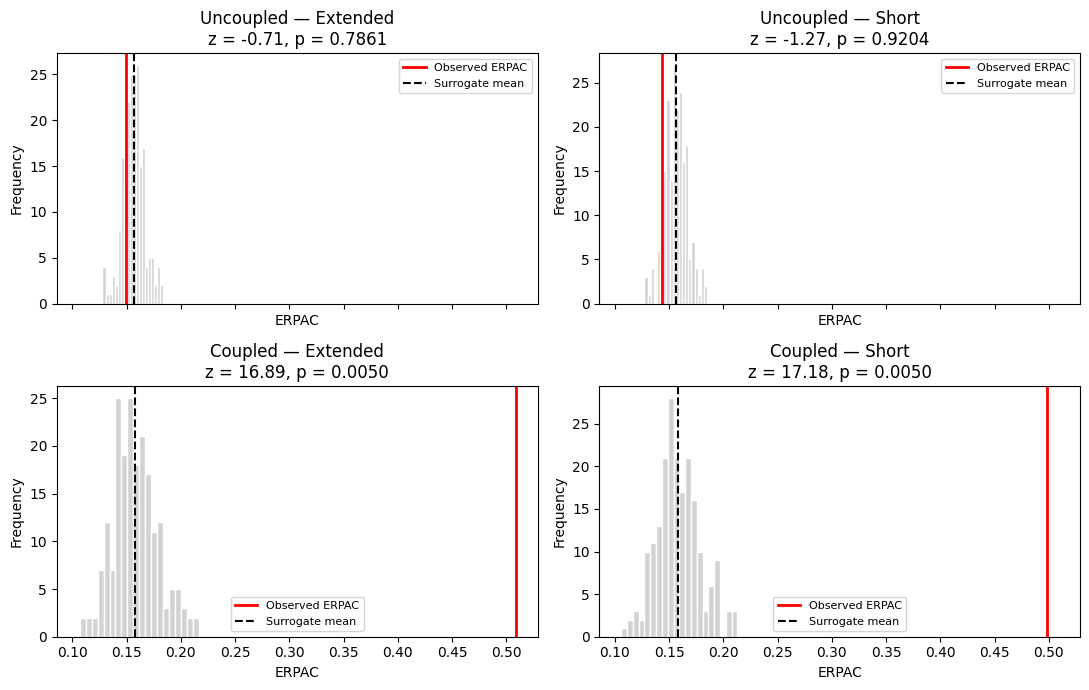

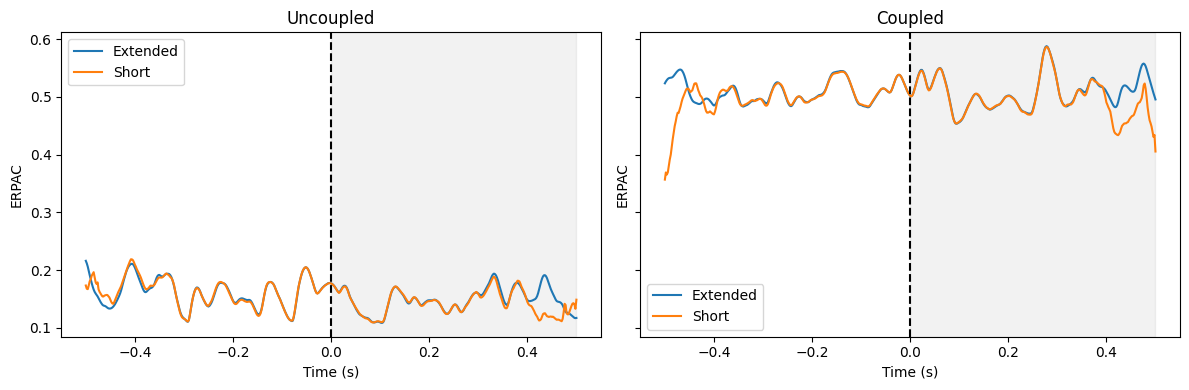

In [7]:
# Plot surrogate distributions
fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7),
    sharex=True
)

for ax, ((control, method), r) in zip(
    axes.flat, results.items()
):

    ax.hist(
        r["surrogate_values"],
        bins=20,
        color="lightgrey",
        edgecolor="white"
    )

    ax.axvline(
        r["observed"],
        color="red",
        linewidth=2,
        label="Observed ERPAC"
    )

    ax.axvline(
        r["surrogate_mean"],
        color="black",
        linestyle="--",
        label="Surrogate mean"
    )

    ax.set_title(
        f"{control} — {method}\n"
        f"z = {r['z']:.2f}, "
        f"p = {r['p_empirical']:.4f}"
    )

    ax.set_xlabel("ERPAC")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Examine time-resolved boundary effects
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    sharey=True
)

for ax, control in zip(
    axes, ["Uncoupled", "Coupled"]
):

    for method in ["Extended", "Short"]:

        observed_map = results[
            (control, method)
        ]["observed_map"]

        # Average over phase and amplitude frequencies
        erpac_timecourse = observed_map.mean(
            axis=(0, 1)
        )

        ax.plot(
            short_times,
            erpac_timecourse,
            label=method
        )

    ax.axvline(0, color="black", linestyle="--")
    ax.axvspan(0, 0.5, color="grey", alpha=0.1)

    ax.set_title(control)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("ERPAC")
    ax.legend()

plt.tight_layout()
plt.show()

In [8]:
# Compare ERPAC within individual time windows
# Time windows used in Study 2 LMMs
time_windows = {
    "plan": {
        "early": (0.0, 0.2),
        "middle": (0.2, 0.35),
        "late": (0.35, 0.5)
    },
    "go": {
        "early": (0.0, 0.15),
        "middle": (0.15, 0.3),
        "late": (0.3, 0.5)
    }
}

rows = []

for control in ["Uncoupled", "Coupled"]:

    extended = results[
        (control, "Extended")
    ]["observed_map"]

    short = results[
        (control, "Short")
    ]["observed_map"]

    for stage, windows in time_windows.items():

        for window, (tmin, tmax) in windows.items():

            mask = (
                (short_times >= tmin)
                & (short_times < tmax)
            )

            extended_mean = extended[..., mask].mean()
            short_mean = short[..., mask].mean()

            difference = short_mean - extended_mean

            relative_difference = (
                difference / extended_mean * 100
            )

            rows.append({
                "control": control,
                "task_stage": stage,
                "time_window": window,
                "extended_erpac": extended_mean,
                "short_erpac": short_mean,
                "difference": difference,
                "relative_difference_pct": relative_difference
            })

window_comparison = pd.DataFrame(rows)

print(
    window_comparison.round(6).to_string(index=False)
)

  control task_stage time_window  extended_erpac  short_erpac  difference  relative_difference_pct
Uncoupled       plan       early        0.143528     0.143595    0.000067                 0.046666
Uncoupled       plan      middle        0.151701     0.149441   -0.002260                -1.489587
Uncoupled       plan        late        0.154308     0.136835   -0.017474               -11.323856
Uncoupled         go       early        0.142702     0.142750    0.000048                 0.033892
Uncoupled         go      middle        0.142556     0.142343   -0.000212                -0.149049
Uncoupled         go        late        0.159092     0.144482   -0.014610                -9.183361
  Coupled       plan       early        0.501368     0.501001   -0.000366                -0.073085
  Coupled       plan      middle        0.509586     0.508800   -0.000787                -0.154355
  Coupled       plan        late        0.517342     0.483451   -0.033891                -6.551079
  Coupled 

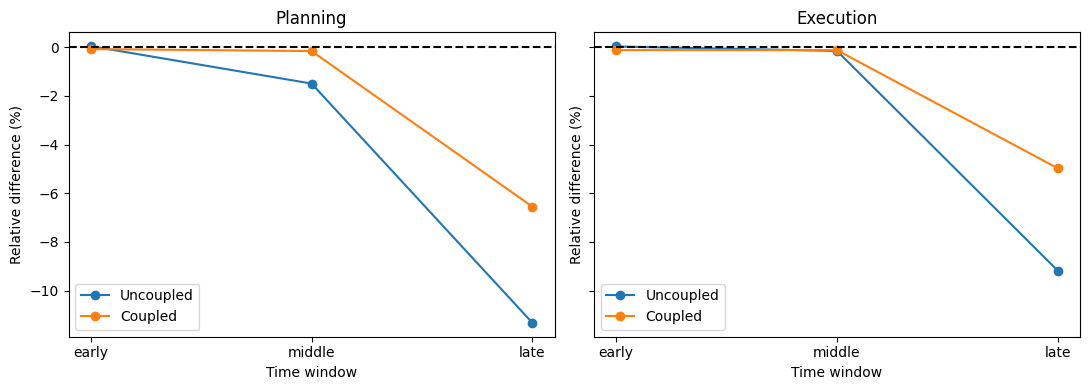

In [9]:
# Visualize the relative estimation error
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4),
    sharey=True
)

for ax, stage in zip(axes, ["plan", "go"]):

    for control in ["Uncoupled", "Coupled"]:

        d = window_comparison[
            (window_comparison["task_stage"] == stage)
            & (window_comparison["control"] == control)
        ]

        ax.plot(
            d["time_window"],
            d["relative_difference_pct"],
            marker="o",
            label=control
        )

    ax.axhline(
        0,
        color="black",
        linestyle="--"
    )

    ax.set_title(
        "Planning" if stage == "plan" else "Execution"
    )

    ax.set_xlabel("Time window")
    ax.set_ylabel("Relative difference (%)")
    ax.legend()

plt.tight_layout()
plt.show()

In [12]:
# Calculate window-specific surrogate statistics
window_results = []

for control, x in [
    ("Uncoupled", x_uncoupled),
    ("Coupled", x_coupled)
]:

    for method, extended in [
        ("Extended", True),
        ("Short", False)
    ]:

        print(f"Running: {control}, {method}")

        pha, amp = extract_phase_amplitude(
            x,
            extended=extended
        )

        df = validate_erpac_windows(pha, amp)

        df["control"] = control
        df["filtering"] = method

        window_results.append(df)

window_z_results = pd.concat(
    window_results,
    ignore_index=True
)

print(
    window_z_results.round(6).to_string(index=False)
)


Running: Uncoupled, Extended
Running: Uncoupled, Short
Running: Coupled, Extended
Running: Coupled, Short
task_stage time_window  observed  surrogate_mean  surrogate_sd         z  p_empirical   control filtering
      plan       early  0.143528        0.156522      0.014732 -0.882003     0.835821 Uncoupled  Extended
      plan      middle  0.151701        0.157401      0.018385 -0.310080     0.597015 Uncoupled  Extended
      plan        late  0.154308        0.155150      0.018480 -0.045526     0.487562 Uncoupled  Extended
        go       early  0.142702        0.156391      0.017552 -0.779927     0.781095 Uncoupled  Extended
        go      middle  0.142556        0.157722      0.017283 -0.877552     0.805970 Uncoupled  Extended
        go        late  0.159092        0.155350      0.015643  0.239205     0.412935 Uncoupled  Extended
      plan       early  0.143595        0.156586      0.014744 -0.881073     0.835821 Uncoupled     Short
      plan      middle  0.149441        0.1574

In [13]:
# Compare z-scores directly
z_comparison = window_z_results.pivot(
    index=["control", "task_stage", "time_window"],
    columns="filtering",
    values="z"
).reset_index()

z_comparison["z_difference"] = (
    z_comparison["Short"]
    - z_comparison["Extended"]
)

window_order = ["early", "middle", "late"]

z_comparison["time_window"] = pd.Categorical(
    z_comparison["time_window"],
    categories=window_order,
    ordered=True
)

z_comparison = z_comparison.sort_values(
    ["control", "task_stage", "time_window"]
)

print(
    z_comparison.round(4).to_string(index=False)
)

  control task_stage time_window  Extended   Short  z_difference
  Coupled         go       early   14.5398 14.5143       -0.0255
  Coupled         go      middle   15.2354 15.2474        0.0119
  Coupled         go        late   14.8695 14.3450       -0.5245
  Coupled       plan       early   14.9964 14.9900       -0.0064
  Coupled       plan      middle   14.8526 14.8382       -0.0144
  Coupled       plan        late   14.4859 13.1523       -1.3336
Uncoupled         go       early   -0.7799 -0.7805       -0.0006
Uncoupled         go      middle   -0.8776 -0.8919       -0.0144
Uncoupled         go        late    0.2392 -0.6896       -0.9288
Uncoupled       plan       early   -0.8820 -0.8811        0.0009
Uncoupled       plan      middle   -0.3101 -0.4340       -0.1239
Uncoupled       plan        late   -0.0455 -0.9941       -0.9486


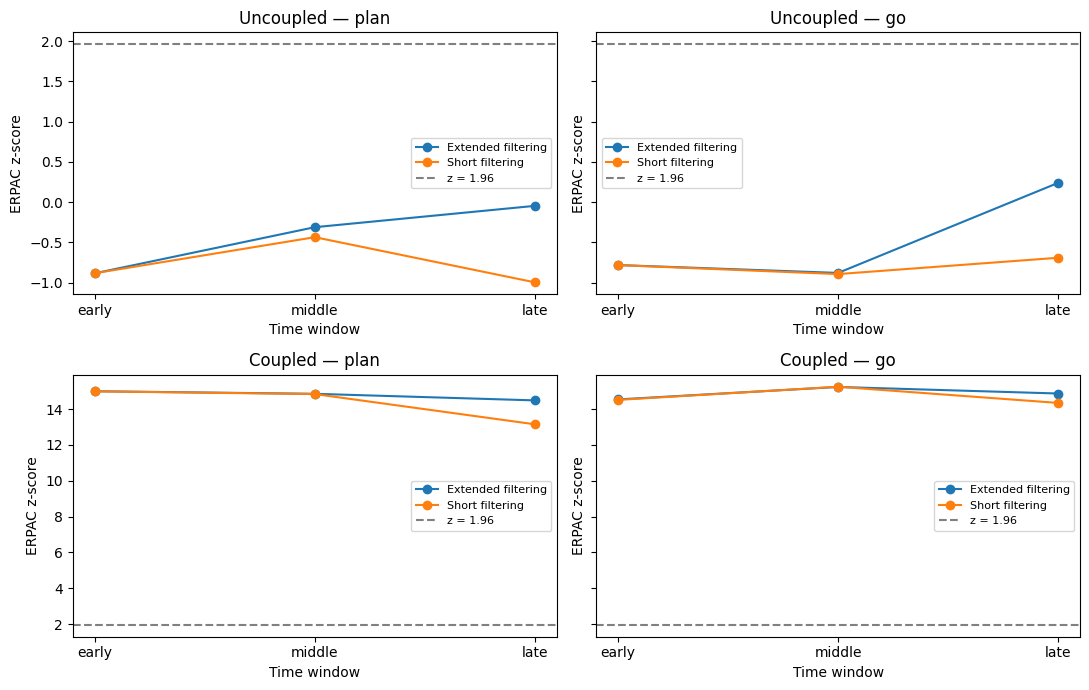

In [14]:
# Visualize z-normalized ERPAC
fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7),
    sharey="row"
)

for i, control in enumerate(
    ["Uncoupled", "Coupled"]
):

    for j, stage in enumerate(["plan", "go"]):

        ax = axes[i, j]

        d = z_comparison[
            (z_comparison["control"] == control)
            & (z_comparison["task_stage"] == stage)
        ]

        ax.plot(
            d["time_window"],
            d["Extended"],
            marker="o",
            label="Extended filtering"
        )

        ax.plot(
            d["time_window"],
            d["Short"],
            marker="o",
            label="Short filtering"
        )

        ax.axhline(
            1.96,
            color="grey",
            linestyle="--",
            label="z = 1.96"
        )

        ax.set_title(f"{control} — {stage}")
        ax.set_xlabel("Time window")
        ax.set_ylabel("ERPAC z-score")
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [15]:
# Evaluate different exclusion durations
exclusion_durations = [0, 50, 75, 100, 125, 150]

rows = []

for control in ["Uncoupled", "Coupled"]:

    extended = results[
        (control, "Extended")
    ]["observed_map"]

    short = results[
        (control, "Short")
    ]["observed_map"]

    for exclusion_ms in exclusion_durations:

        tmax = 0.5 - exclusion_ms / 1000

        mask = (
            (short_times >= 0)
            & (short_times < tmax)
        )

        extended_values = extended[..., mask]
        short_values = short[..., mask]

        extended_mean = extended_values.mean()
        short_mean = short_values.mean()

        # Relative difference in average ERPAC
        relative_diff = (
            (short_mean - extended_mean)
            / extended_mean * 100
        )

        # RMSE across the averaged ERPAC time courses
        extended_tc = extended_values.mean(axis=(0, 1))
        short_tc = short_values.mean(axis=(0, 1))

        rmse = np.sqrt(
            np.mean((short_tc - extended_tc)**2)
        )

        rows.append({
            "control": control,
            "excluded_ms": exclusion_ms,
            "analysis_end_ms": round(tmax * 1000),
            "extended_erpac": extended_mean,
            "short_erpac": short_mean,
            "relative_difference_pct": relative_diff,
            "rmse": rmse
        })

exclusion_comparison = pd.DataFrame(rows)

print(
    exclusion_comparison.round(6).to_string(index=False)
)

  control  excluded_ms  analysis_end_ms  extended_erpac  short_erpac  relative_difference_pct     rmse
Uncoupled            0              500        0.149214     0.143321                -3.949513 0.017062
Uncoupled           50              450        0.150674     0.145345                -3.536913 0.015838
Uncoupled           75              425        0.148907     0.146750                -1.448412 0.006988
Uncoupled          100              400        0.148764     0.147813                -0.639053 0.002906
Uncoupled          125              375        0.147512     0.146368                -0.775631 0.002904
Uncoupled          150              350        0.147030     0.146100                -0.632640 0.002659
  Coupled            0              500        0.508626     0.498076                -2.074216 0.023345
  Coupled           50              450        0.506298     0.500315                -1.181633 0.017031
  Coupled           75              425        0.505861     0.503059     

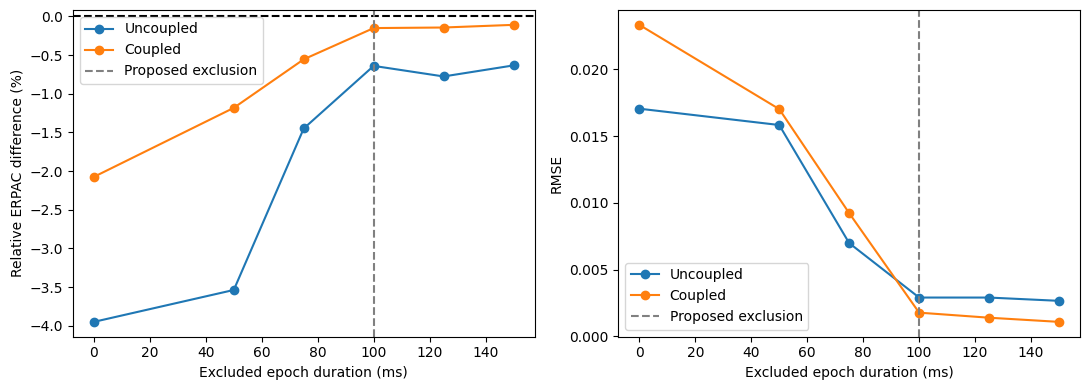

In [16]:
# Plot the results
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for control in ["Uncoupled", "Coupled"]:

    d = exclusion_comparison[
        exclusion_comparison["control"] == control
    ]

    axes[0].plot(
        d["excluded_ms"],
        d["relative_difference_pct"],
        marker="o",
        label=control
    )

    axes[1].plot(
        d["excluded_ms"],
        d["rmse"],
        marker="o",
        label=control
    )

axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_ylabel("Relative ERPAC difference (%)")
axes[1].set_ylabel("RMSE")

for ax in axes:

    ax.axvline(
        100,
        color="grey",
        linestyle="--",
        label="Proposed exclusion"
    )

    ax.set_xlabel("Excluded epoch duration (ms)")
    ax.legend()

plt.tight_layout()
plt.show()

# Sensitivity to coupling strength

In [19]:
MODULATION_DEPTHS = [
    0.0, 0.05, 0.10, 0.20,
    0.40, 0.60, 0.80
]

N_REPEATS = 20
VALIDATION_SEED = 2026

validation_windows = {
    "overall": (0.0, 0.4),
    "early": (0.0, 0.15),
    "middle": (0.15, 0.275),
    "late": (0.275, 0.4)
}

window_masks = {
    name: (
        (short_times >= tmin)
        & (short_times < tmax)
    )
    for name, (tmin, tmax)
    in validation_windows.items()
}

for name, mask in window_masks.items():
    print(name, mask.sum(), "samples")

def generate_base_signals(seed):

    rng = np.random.default_rng(seed)

    theta_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(N_TRIALS, 1)
    )

    gamma_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(N_TRIALS, 1)
    )

    theta_phase = (
        2 * np.pi * F_THETA * times[None, :]
        + theta_offsets
    )

    theta = np.sin(theta_phase)

    gamma = np.sin(
        2 * np.pi * F_GAMMA * times[None, :]
        + gamma_offsets
    )

    noise = rng.normal(
        0, 0.5,
        size=theta.shape
    )

    return theta_phase, theta, gamma, noise

def introduce_coupling(
    theta_phase,
    theta,
    gamma,
    noise,
    modulation_depth
):

    gamma_envelope = (
        1
        + modulation_depth * np.cos(theta_phase)
    )

    x = theta + gamma_envelope * gamma + noise

    return x

overall 200 samples
early 75 samples
middle 63 samples
late 62 samples


In [20]:
# ERPAC and surrogate normalization
def evaluate_coupling_strength(
    pha, amp, permutations
):

    observed_map = compute_erpac(pha, amp)

    observed_values = {
        name: observed_map[..., mask].mean()
        for name, mask in window_masks.items()
    }

    surrogate_values = {
        name: np.empty(len(permutations))
        for name in window_masks
    }

    for i, perm in enumerate(permutations):

        amp_shuffled = amp[:, perm, :]

        surrogate_map = compute_erpac(
            pha, amp_shuffled
        )

        for name, mask in window_masks.items():

            surrogate_values[name][i] = (
                surrogate_map[..., mask].mean()
            )

    rows = []

    for name in window_masks:

        observed = observed_values[name]
        sur = surrogate_values[name]

        sur_mean = sur.mean()
        sur_sd = sur.std(ddof=1)

        if not np.isfinite(sur_sd) or sur_sd <= 0:
            raise ValueError(
                f"Invalid surrogate SD: {name}"
            )

        z = (observed - sur_mean) / sur_sd

        p_empirical = (
            1 + np.sum(sur >= observed)
        ) / (len(sur) + 1)

        rows.append({
            "time_window": name,
            "observed": observed,
            "surrogate_mean": sur_mean,
            "surrogate_sd": sur_sd,
            "surrogate_skewness": skew(sur),
            "z": z,
            "p_empirical": p_empirical,
            "detected_z": z > 1.96,
            "detected_empirical": p_empirical < 0.05
        })

    return pd.DataFrame(rows)

# Run repeated simulations
from time import perf_counter

all_results = []

start = perf_counter()

for repeat in range(N_REPEATS):

    seed = VALIDATION_SEED + repeat

    # Generate independent synthetic signals
    base_signals = generate_base_signals(seed)

    # Same trial permutations across modulation depths
    rng_sur = np.random.default_rng(seed + 10000)

    permutations = np.stack([
        rng_sur.permutation(N_TRIALS)
        for _ in range(N_SURROGATES)
    ])

    for depth in MODULATION_DEPTHS:

        x = introduce_coupling(
            *base_signals,
            modulation_depth=depth
        )

        # Filter the original available 1 s epoch
        pha, amp = extract_phase_amplitude(
            x,
            extended=False
        )

        df = evaluate_coupling_strength(
            pha,
            amp,
            permutations
        )

        df["repeat"] = repeat + 1
        df["modulation_depth"] = depth

        all_results.append(df)

    print(
        f"Completed repeat {repeat + 1}/{N_REPEATS}"
        f" | Elapsed: {(perf_counter() - start)/60:.1f} min"
    )

strength_results = pd.concat(
    all_results,
    ignore_index=True
)

print("Validation completed.")
print(strength_results.shape)

# Summarise the results
strength_summary = (
    strength_results
    .groupby(
        ["modulation_depth", "time_window"],
        as_index=False
    )
    .agg(
        observed_mean=("observed", "mean"),
        observed_SD=("observed", "std"),

        surrogate_mean=("surrogate_mean", "mean"),
        surrogate_SD_mean=("surrogate_sd", "mean"),

        z_mean=("z", "mean"),
        z_SD=("z", "std"),

        mean_skewness=("surrogate_skewness", "mean"),

        detection_rate_z=("detected_z", "mean"),
        detection_rate_empirical=(
            "detected_empirical", "mean"
        ),

        n_repeats=("repeat", "nunique")
    )
)

strength_summary["detection_rate_z"] *= 100

strength_summary["detection_rate_empirical"] *= 100

overall_summary = strength_summary[
    strength_summary["time_window"] == "overall"
]

print(
    overall_summary.round(4).to_string(index=False)
)

Completed repeat 1/20 | Elapsed: 0.5 min
Completed repeat 2/20 | Elapsed: 1.0 min
Completed repeat 3/20 | Elapsed: 1.5 min
Completed repeat 4/20 | Elapsed: 2.0 min
Completed repeat 5/20 | Elapsed: 2.5 min
Completed repeat 6/20 | Elapsed: 3.0 min
Completed repeat 7/20 | Elapsed: 3.5 min
Completed repeat 8/20 | Elapsed: 4.2 min
Completed repeat 9/20 | Elapsed: 5.1 min
Completed repeat 10/20 | Elapsed: 6.0 min
Completed repeat 11/20 | Elapsed: 6.7 min
Completed repeat 12/20 | Elapsed: 7.2 min
Completed repeat 13/20 | Elapsed: 7.7 min
Completed repeat 14/20 | Elapsed: 8.2 min
Completed repeat 15/20 | Elapsed: 8.7 min
Completed repeat 16/20 | Elapsed: 9.2 min
Completed repeat 17/20 | Elapsed: 9.6 min
Completed repeat 18/20 | Elapsed: 10.1 min
Completed repeat 19/20 | Elapsed: 10.6 min
Completed repeat 20/20 | Elapsed: 11.0 min
Validation completed.
(560, 11)
 modulation_depth time_window  observed_mean  observed_SD  surrogate_mean  surrogate_SD_mean  z_mean   z_SD  mean_skewness  detection_

Plotting

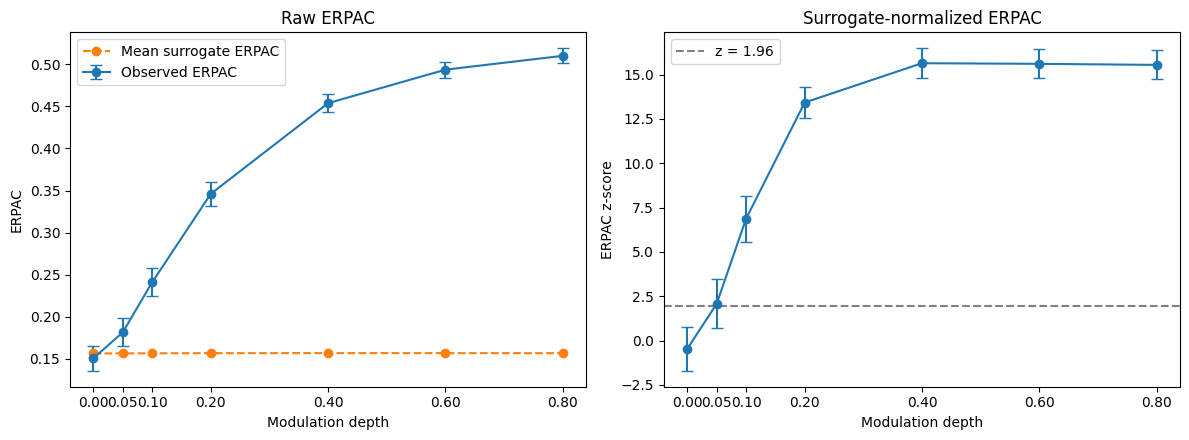

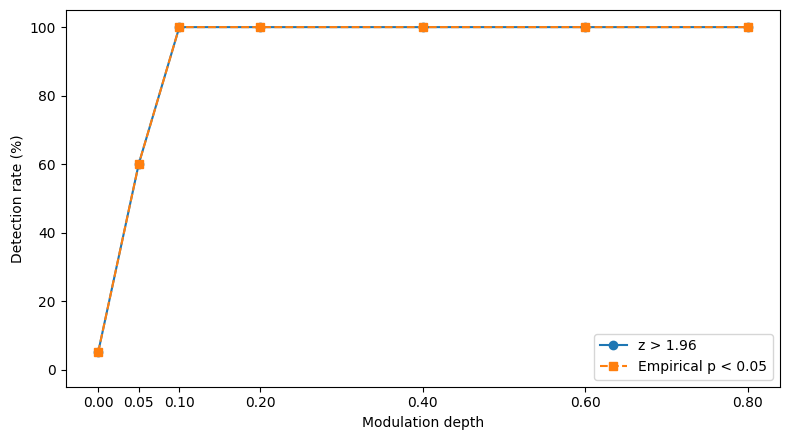

In [21]:
# Raw ERPAC and surrogate-normalized ERPAC
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5)
)

d = overall_summary

# Raw ERPAC
axes[0].errorbar(
    d["modulation_depth"],
    d["observed_mean"],
    yerr=d["observed_SD"],
    marker="o",
    capsize=4,
    label="Observed ERPAC"
)

axes[0].plot(
    d["modulation_depth"],
    d["surrogate_mean"],
    marker="o",
    linestyle="--",
    label="Mean surrogate ERPAC"
)

axes[0].set_ylabel("ERPAC")
axes[0].set_title("Raw ERPAC")
axes[0].legend()

# Z-normalized ERPAC
axes[1].errorbar(
    d["modulation_depth"],
    d["z_mean"],
    yerr=d["z_SD"],
    marker="o",
    capsize=4
)

axes[1].axhline(
    1.96,
    color="grey",
    linestyle="--",
    label="z = 1.96"
)

axes[1].set_ylabel("ERPAC z-score")
axes[1].set_title("Surrogate-normalized ERPAC")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Modulation depth")
    ax.set_xticks(MODULATION_DEPTHS)

plt.tight_layout()
plt.show()

# Coupling detection rates
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    d["modulation_depth"],
    d["detection_rate_z"],
    marker="o",
    label="z > 1.96"
)

ax.plot(
    d["modulation_depth"],
    d["detection_rate_empirical"],
    marker="s",
    linestyle="--",
    label="Empirical p < 0.05"
)

ax.set_xlabel("Modulation depth")
ax.set_ylabel("Detection rate (%)")

ax.set_ylim(-5, 105)
ax.set_xticks(MODULATION_DEPTHS)

ax.legend()

plt.tight_layout()
plt.show()

Compare the revised time windows

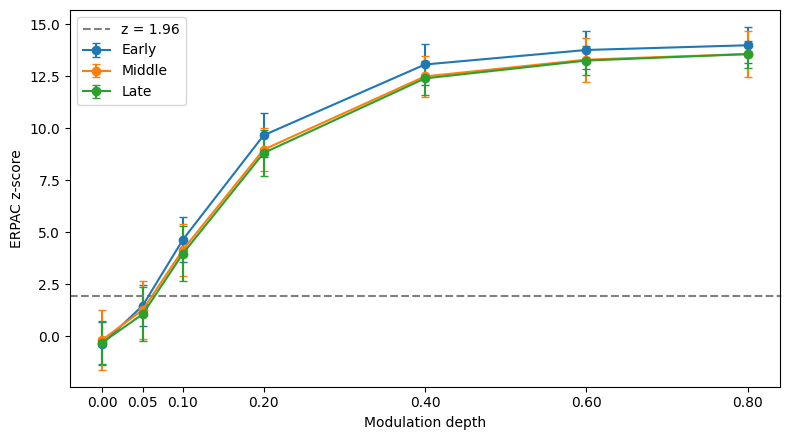

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for window in ["early", "middle", "late"]:

    d_window = strength_summary[
        strength_summary["time_window"] == window
    ]

    ax.errorbar(
        d_window["modulation_depth"],
        d_window["z_mean"],
        yerr=d_window["z_SD"],
        marker="o",
        capsize=3,
        label=window.capitalize()
    )

ax.axhline(
    1.96,
    color="grey",
    linestyle="--",
    label="z = 1.96"
)

ax.set_xlabel("Modulation depth")
ax.set_ylabel("ERPAC z-score")
ax.set_xticks(MODULATION_DEPTHS)

ax.legend()

plt.tight_layout()
plt.show()

Save validation results

In [23]:
from pathlib import Path

validation_dir = Path("validation_coupling_strength")

validation_dir.mkdir(
    parents=True, exist_ok=True
)

strength_results.to_csv(
    validation_dir / "strength_validation_full.csv",
    index=False
)

strength_summary.to_csv(
    validation_dir / "strength_validation_summary.csv",
    index=False
)

In [24]:
overall_summary

,modulation_depth,time_window,observed_mean,observed_SD,surrogate_mean,surrogate_SD_mean,z_mean,z_SD,mean_skewness,detection_rate_z,detection_rate_empirical,n_repeats
3,0.00,overall,0.150929,0.014782,0.156512,0.012052,-0.459001,1.232960,0.088701,5.0,5.0,20
7,0.05,overall,0.181666,0.016699,0.156605,0.012083,2.077050,1.371759,0.110678,60.0,60.0,20
11,0.10,overall,0.241042,0.016575,0.156704,0.012294,6.861521,1.308804,0.155136,100.0,100.0,20
15,0.20,overall,0.346097,0.014093,0.156856,0.014111,13.422674,0.895252,0.327284,100.0,100.0,20
19,0.40,overall,0.453819,0.010487,0.156944,0.019026,15.639830,0.833054,0.498977,100.0,100.0,20
23,0.60,overall,0.493599,0.009296,0.156910,0.021625,15.605527,0.816316,0.491846,100.0,100.0,20
27,0.80,overall,0.510047,0.008782,0.156863,0.022774,15.544820,0.815733,0.476738,100.0,100.0,20


# Sensitivity to trial counts validation

In [25]:
TRIAL_COUNTS = [
    20, 30, 40, 50, 66, 80, 100
]

TRIAL_MODULATION_DEPTHS = [
    0.0, 0.05, 0.10, 0.20
]

N_TRIAL_REPEATS = 20
MAX_TRIALS = max(TRIAL_COUNTS)

TRIAL_VALIDATION_SEED = 3026

def generate_base_signals_trials(seed, n_trials):

    rng = np.random.default_rng(seed)

    theta_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(n_trials, 1)
    )

    gamma_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(n_trials, 1)
    )

    theta_phase = (
        2 * np.pi * F_THETA * times[None, :]
        + theta_offsets
    )

    theta = np.sin(theta_phase)

    gamma = np.sin(
        2 * np.pi * F_GAMMA * times[None, :]
        + gamma_offsets
    )

    noise = rng.normal(
        0, 0.5,
        size=theta.shape
    )

    return theta_phase, theta, gamma, noise



In [26]:
from time import perf_counter

all_trial_results = []

start = perf_counter()

for repeat in range(N_TRIAL_REPEATS):

    seed = TRIAL_VALIDATION_SEED + repeat

    # Generate the maximum number of trials
    base_signals = generate_base_signals_trials(
        seed=seed,
        n_trials=MAX_TRIALS
    )

    # Randomized trial order for nested subsets
    rng_trials = np.random.default_rng(seed + 10000)

    trial_order = rng_trials.permutation(MAX_TRIALS)

    # Generate surrogate permutations for each trial count
    # Reuse them across modulation depths
    permutations_by_count = {}

    for n_trials in TRIAL_COUNTS:

        rng_sur = np.random.default_rng(
            seed + 20000 + n_trials
        )

        permutations_by_count[n_trials] = np.stack([
            rng_sur.permutation(n_trials)
            for _ in range(N_SURROGATES)
        ])

    for depth in TRIAL_MODULATION_DEPTHS:

        # Introduce coupling
        x = introduce_coupling(
            *base_signals,
            modulation_depth=depth
        )

        # Filter all 100 trials
        pha_full, amp_full = extract_phase_amplitude(
            x,
            extended=False
        )

        for n_trials in TRIAL_COUNTS:

            # Select a subset of trials
            indices = trial_order[:n_trials]

            pha = pha_full[:, indices, :]
            amp = amp_full[:, indices, :]

            # Retrieve matching surrogate permutations
            permutations = permutations_by_count[n_trials]

            # ERPAC and surrogate normalization
            df = evaluate_coupling_strength(
                pha,
                amp,
                permutations
            )

            df["repeat"] = repeat + 1
            df["modulation_depth"] = depth
            df["n_trials"] = n_trials

            all_trial_results.append(df)

    print(
        f"Completed repeat "
        f"{repeat + 1}/{N_TRIAL_REPEATS}"
        f" | Elapsed: "
        f"{(perf_counter() - start)/60:.1f} min"
    )

trial_results = pd.concat(
    all_trial_results,
    ignore_index=True
)

print("Validation completed.")
print(trial_results.shape)

trial_summary = (
    trial_results
    .groupby(
        [
            "n_trials",
            "modulation_depth",
            "time_window"
        ],
        as_index=False
    )
    .agg(
        observed_mean=("observed", "mean"),
        observed_SD=("observed", "std"),

        surrogate_mean=("surrogate_mean", "mean"),
        surrogate_SD_mean=("surrogate_sd", "mean"),

        z_mean=("z", "mean"),
        z_SD=("z", "std"),

        mean_skewness=("surrogate_skewness", "mean"),

        detection_rate_z=("detected_z", "mean"),

        detection_rate_empirical=(
            "detected_empirical", "mean"
        ),

        n_repeats=("repeat", "nunique")
    )
)

trial_summary["detection_rate_z"] *= 100

trial_summary["detection_rate_empirical"] *= 100

trial_overall = trial_summary[
    trial_summary["time_window"] == "overall"
].copy()

print(
    trial_overall.round(4).to_string(index=False)
)

Completed repeat 1/20 | Elapsed: 2.4 min
Completed repeat 2/20 | Elapsed: 4.7 min
Completed repeat 3/20 | Elapsed: 6.1 min
Completed repeat 4/20 | Elapsed: 8.8 min
Completed repeat 5/20 | Elapsed: 11.8 min
Completed repeat 6/20 | Elapsed: 14.7 min
Completed repeat 7/20 | Elapsed: 17.2 min
Completed repeat 8/20 | Elapsed: 18.6 min
Completed repeat 9/20 | Elapsed: 20.0 min
Completed repeat 10/20 | Elapsed: 21.4 min
Completed repeat 11/20 | Elapsed: 22.8 min
Completed repeat 12/20 | Elapsed: 24.2 min
Completed repeat 13/20 | Elapsed: 25.7 min
Completed repeat 14/20 | Elapsed: 27.1 min
Completed repeat 15/20 | Elapsed: 28.5 min
Completed repeat 16/20 | Elapsed: 29.9 min
Completed repeat 17/20 | Elapsed: 31.3 min
Completed repeat 18/20 | Elapsed: 32.7 min
Completed repeat 19/20 | Elapsed: 34.1 min
Completed repeat 20/20 | Elapsed: 35.5 min
Validation completed.
(2240, 12)
 n_trials  modulation_depth time_window  observed_mean  observed_SD  surrogate_mean  surrogate_SD_mean  z_mean   z_SD  m

Plotting

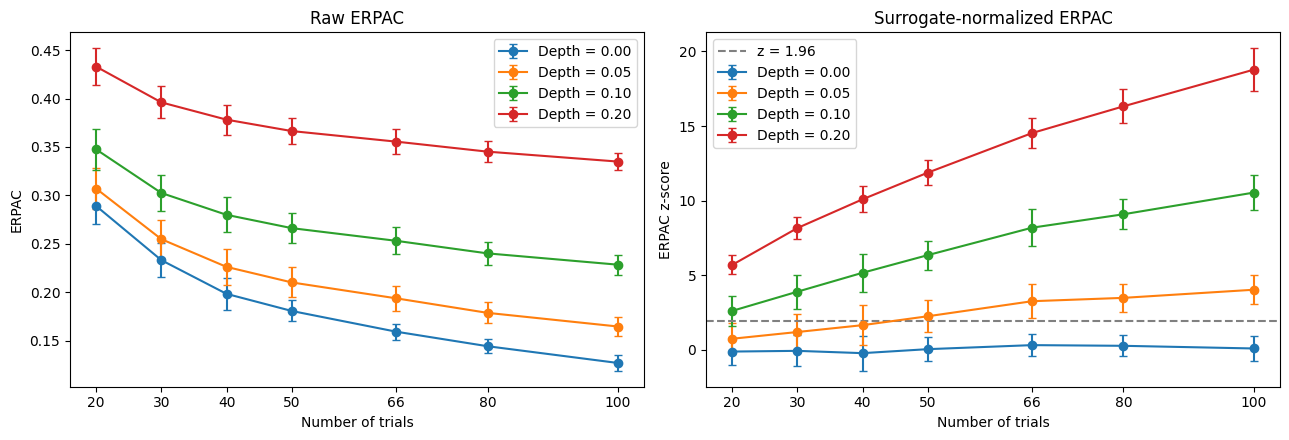

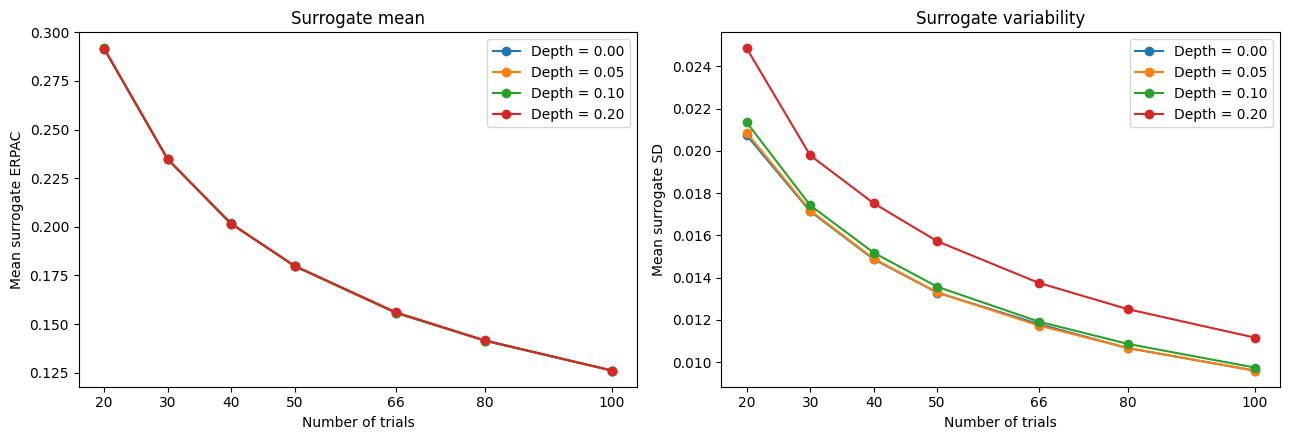

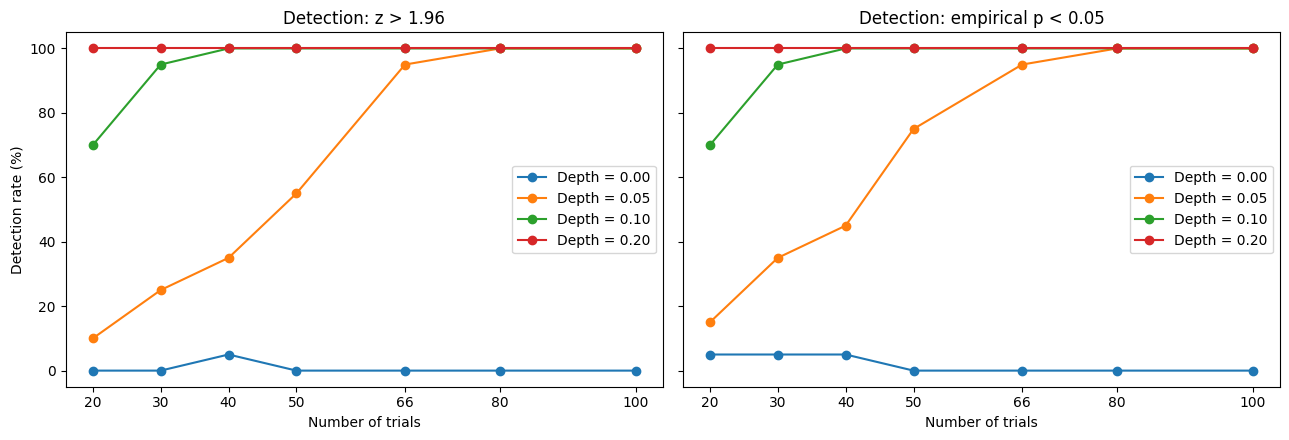

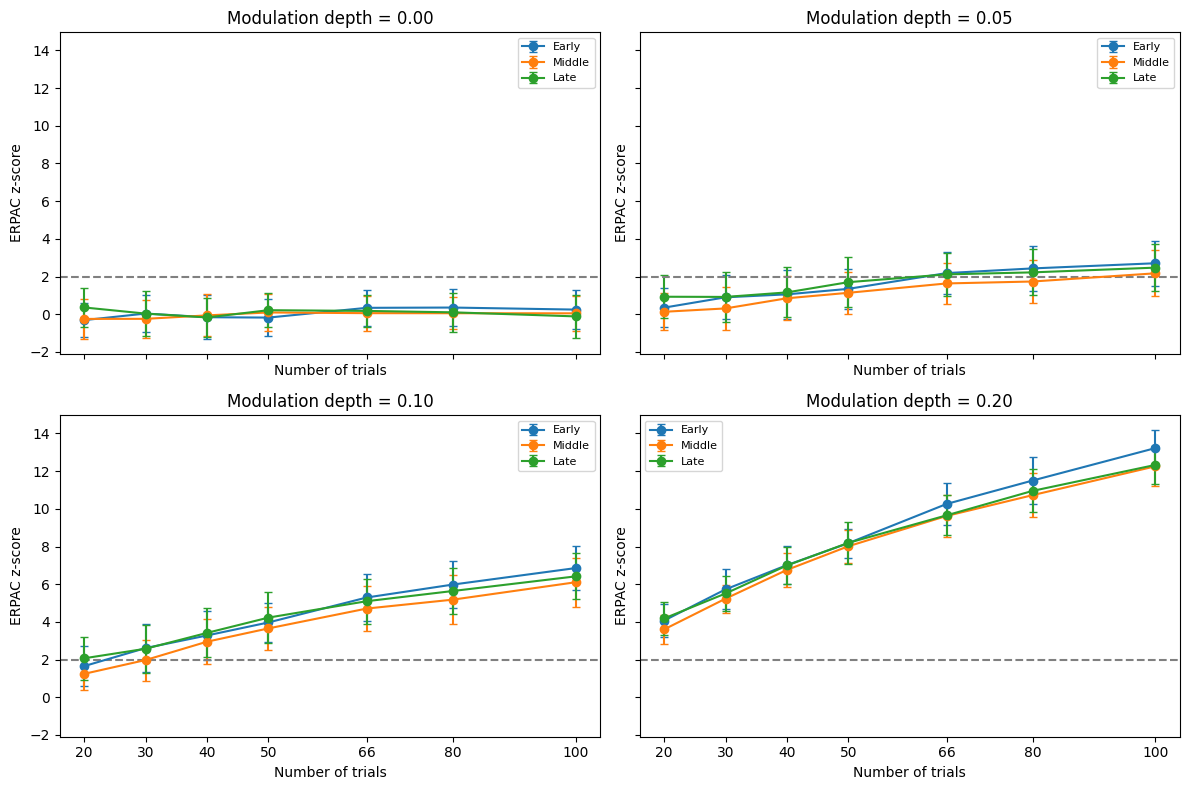

In [27]:
# Raw ERPAC and surrogate-normalized ERPAC
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

for depth in TRIAL_MODULATION_DEPTHS:

    d = trial_overall[
        trial_overall["modulation_depth"] == depth
    ]

    # Raw ERPAC
    axes[0].errorbar(
        d["n_trials"],
        d["observed_mean"],
        yerr=d["observed_SD"],
        marker="o",
        capsize=3,
        label=f"Depth = {depth:.2f}"
    )

    # Z-normalized ERPAC
    axes[1].errorbar(
        d["n_trials"],
        d["z_mean"],
        yerr=d["z_SD"],
        marker="o",
        capsize=3,
        label=f"Depth = {depth:.2f}"
    )

axes[0].set_title("Raw ERPAC")
axes[0].set_ylabel("ERPAC")

axes[1].axhline(
    1.96,
    color="grey",
    linestyle="--",
    label="z = 1.96"
)

axes[1].set_title("Surrogate-normalized ERPAC")
axes[1].set_ylabel("ERPAC z-score")

for ax in axes:

    ax.set_xlabel("Number of trials")
    ax.set_xticks(TRIAL_COUNTS)
    ax.legend()

plt.tight_layout()
plt.show()

# Surrogate distribution characteristics
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

for depth in TRIAL_MODULATION_DEPTHS:

    d = trial_overall[
        trial_overall["modulation_depth"] == depth
    ]

    axes[0].plot(
        d["n_trials"],
        d["surrogate_mean"],
        marker="o",
        label=f"Depth = {depth:.2f}"
    )

    axes[1].plot(
        d["n_trials"],
        d["surrogate_SD_mean"],
        marker="o",
        label=f"Depth = {depth:.2f}"
    )

axes[0].set_title("Surrogate mean")
axes[0].set_ylabel("Mean surrogate ERPAC")

axes[1].set_title("Surrogate variability")
axes[1].set_ylabel("Mean surrogate SD")

for ax in axes:

    ax.set_xlabel("Number of trials")
    ax.set_xticks(TRIAL_COUNTS)
    ax.legend()

plt.tight_layout()
plt.show()

# Coupling detection rates
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    sharey=True
)

for depth in TRIAL_MODULATION_DEPTHS:

    d = trial_overall[
        trial_overall["modulation_depth"] == depth
    ]

    axes[0].plot(
        d["n_trials"],
        d["detection_rate_z"],
        marker="o",
        label=f"Depth = {depth:.2f}"
    )

    axes[1].plot(
        d["n_trials"],
        d["detection_rate_empirical"],
        marker="o",
        label=f"Depth = {depth:.2f}"
    )

axes[0].set_title("Detection: z > 1.96")
axes[1].set_title("Detection: empirical p < 0.05")

axes[0].set_ylabel("Detection rate (%)")

for ax in axes:

    ax.set_xlabel("Number of trials")
    ax.set_xticks(TRIAL_COUNTS)
    ax.set_ylim(-5, 105)
    ax.legend()

plt.tight_layout()
plt.show()

# Compare individual time windows
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

for ax, depth in zip(
    axes.flat,
    TRIAL_MODULATION_DEPTHS
):

    for window in ["early", "middle", "late"]:

        d = trial_summary[
            (trial_summary["modulation_depth"] == depth)
            & (trial_summary["time_window"] == window)
        ]

        ax.errorbar(
            d["n_trials"],
            d["z_mean"],
            yerr=d["z_SD"],
            marker="o",
            capsize=3,
            label=window.capitalize()
        )

    ax.axhline(
        1.96,
        color="grey",
        linestyle="--"
    )

    ax.set_title(f"Modulation depth = {depth:.2f}")
    ax.set_xlabel("Number of trials")
    ax.set_ylabel("ERPAC z-score")
    ax.set_xticks(TRIAL_COUNTS)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [29]:
trial_overall

,n_trials,modulation_depth,time_window,observed_mean,observed_SD,surrogate_mean,surrogate_SD_mean,z_mean,z_SD,mean_skewness,detection_rate_z,detection_rate_empirical,n_repeats
3,20,0.00,overall,0.289119,0.018309,0.291657,0.020734,-0.104934,0.887903,0.113736,0.0,5.0,20
7,20,0.05,overall,0.307076,0.020993,0.291737,0.020852,0.751957,1.030903,0.123457,10.0,15.0,20
11,20,0.10,overall,0.347518,0.020915,0.291743,0.021347,2.616297,0.987149,0.136618,70.0,70.0,20
15,20,0.20,overall,0.432912,0.018755,0.291561,0.024849,5.694215,0.636804,0.260285,100.0,100.0,20
19,30,0.00,overall,0.233206,0.017389,0.234754,0.017135,-0.057279,1.041622,0.174250,0.0,5.0,20
23,30,0.05,overall,0.254855,0.019574,0.234743,0.017176,1.203913,1.198876,0.163250,25.0,35.0,20
27,30,0.10,overall,0.302517,0.018997,0.234743,0.017421,3.902676,1.134297,0.161469,95.0,95.0,20
31,30,0.20,overall,0.396002,0.016474,0.234746,0.019786,8.165314,0.725358,0.238178,100.0,100.0,20
35,40,0.00,overall,0.198421,0.016512,0.201712,0.014868,-0.211630,1.169539,0.181374,5.0,5.0,20
39,40,0.05,overall,0.226252,0.018948,0.201680,0.014897,1.662847,1.347857,0.185618,35.0,45.0,20


In [28]:
from pathlib import Path

validation_dir = Path("validation_trial_counts")

validation_dir.mkdir(
    parents=True,
    exist_ok=True
)

trial_results.to_csv(
    validation_dir / "trial_validation_full.csv",
    index=False
)

trial_summary.to_csv(
    validation_dir / "trial_validation_summary.csv",
    index=False
)

Actual trial-count distribution

In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

ERPAC_ROOT = Path(
    r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc"
)

pkl_files = sorted(
    ERPAC_ROOT.rglob("*_pca_roi_tc_erpac_results.pkl")
)

print("Number of pickle files:", len(pkl_files))

# Inspect the first file
with open(pkl_files[0], "rb") as f:
    example = pickle.load(f)

print("\nExample file:", pkl_files[0].name)
print("Couplings:", list(example.keys()))

for coupling, roi_data in example.items():

    print(f"\nCoupling: {coupling}")

    for roi, values in roi_data.items():

        print(
            roi,
            "| n_epochs:", values.get("n_epochs"),
            "| ERPAC shape:", values["erpac"].shape
        )


rows = []

for file_path in pkl_files:

    # Extract group and participant from folder structure
    group = file_path.parent.parent.name
    sub = file_path.parent.name

    # Extract experimental information from filename
    condition_name = (
        file_path.name
        .removeprefix(f"{sub}_")
        .removesuffix("_pca_roi_tc_erpac_results.pkl")
    )

    parts = condition_name.split("_")

    task = parts[0]
    task_stage = parts[1]

    task_block = parts[2] if len(parts) > 2 else ""
    adaptation_split = parts[3] if len(parts) > 3 else ""

    # Load ERPAC results
    with open(file_path, "rb") as f:
        data = pickle.load(f)

    # Collect trial counts across all ROIs and couplings
    epoch_counts = []

    for coupling, roi_data in data.items():

        for roi, values in roi_data.items():

            epoch_counts.append(
                int(values["n_epochs"])
            )

    # Check that trial counts are consistent
    if not epoch_counts:
        raise ValueError(
            f"No trial counts found in {file_path.name}"
        )

    if len(set(epoch_counts)) != 1:
        raise ValueError(
            f"Inconsistent trial counts in {file_path.name}: "
            f"{set(epoch_counts)}"
        )

    rows.append({
        "sub": sub,
        "group": group,
        "task": task,
        "task_stage": task_stage,
        "task_block": task_block,
        "adaptation_split": adaptation_split,
        "n_epochs": epoch_counts[0]
    })

trial_counts = pd.DataFrame(rows)

# Validate uniqueness
key_cols = [
    "sub",
    "group",
    "task",
    "task_stage",
    "task_block",
    "adaptation_split"
]

assert not trial_counts.duplicated(key_cols).any()

print(trial_counts.head(10))

print("\nParticipants:", trial_counts["sub"].nunique())
print("Total observations:", len(trial_counts))

print("\nParticipants per group:")
print(trial_counts.groupby("group")["sub"].nunique())

print("\nTrial-count range:")
print(trial_counts["n_epochs"].describe())

Number of pickle files: 376

Example file: s1_pac_sub12_DeCRAT_go_adaptation_early_pca_roi_tc_erpac_results.pkl
Couplings: ['theta_gamma', 'alpha_gamma', 'beta_gamma']

Coupling: theta_gamma
M1 | n_epochs: 62 | ERPAC shape: (45, 601)
PMC | n_epochs: 62 | ERPAC shape: (45, 601)
S1 | n_epochs: 62 | ERPAC shape: (45, 601)
SMA | n_epochs: 62 | ERPAC shape: (45, 601)

Coupling: alpha_gamma
M1 | n_epochs: 62 | ERPAC shape: (45, 601)
PMC | n_epochs: 62 | ERPAC shape: (45, 601)
S1 | n_epochs: 62 | ERPAC shape: (45, 601)
SMA | n_epochs: 62 | ERPAC shape: (45, 601)

Coupling: beta_gamma
M1 | n_epochs: 62 | ERPAC shape: (45, 601)
PMC | n_epochs: 62 | ERPAC shape: (45, 601)
S1 | n_epochs: 62 | ERPAC shape: (45, 601)
SMA | n_epochs: 62 | ERPAC shape: (45, 601)
            sub group    task task_stage  task_block adaptation_split  \
0  s1_pac_sub12     O  DeCRAT         go  adaptation            early   
1  s1_pac_sub12     O  DeCRAT         go  adaptation             late   
2  s1_pac_sub12     O  

In [3]:
def get_condition(row):

    if row["task"] == "FTT":
        return "FTT"

    if row["task_block"] == "baseline":
        return "DeCRAT baseline"

    if row["task_block"] == "adaptation":
        return f"DeCRAT {row['adaptation_split']}"

    return "Other"


trial_counts["condition"] = trial_counts.apply(
    get_condition,
    axis=1
)

CONDITION_ORDER = [
    "FTT",
    "DeCRAT baseline",
    "DeCRAT early",
    "DeCRAT late"
]

print(
    trial_counts["condition"].value_counts()
)

trial_counts = trial_counts[
    trial_counts["condition"].isin(CONDITION_ORDER)
].copy()

condition
DeCRAT early       94
DeCRAT late        94
DeCRAT baseline    94
FTT                94
Name: count, dtype: int64


In [4]:
trial_count_summary = (
    trial_counts
    .groupby(
        ["group", "condition", "task_stage"],
        as_index=False
    )
    .agg(
        n_participants=("sub", "nunique"),
        min_trials=("n_epochs", "min"),
        q05_trials=("n_epochs", lambda x: x.quantile(0.05)),
        q25_trials=("n_epochs", lambda x: x.quantile(0.25)),
        median_trials=("n_epochs", "median"),
        mean_trials=("n_epochs", "mean"),
        sd_trials=("n_epochs", "std"),
        max_trials=("n_epochs", "max")
    )
)

print(
    trial_count_summary.round(2).to_string(index=False)
)

group       condition task_stage  n_participants  min_trials  q05_trials  q25_trials  median_trials  mean_trials  sd_trials  max_trials
    O DeCRAT baseline         go              24          49       51.75       58.75           61.0        59.92       3.80          64
    O DeCRAT baseline       plan              24          40       42.45       46.00           46.5        47.25       2.89          52
    O    DeCRAT early         go              24          38       51.15       58.00           60.0        58.58       5.32          63
    O    DeCRAT early       plan              24          37       39.30       43.75           46.0        44.83       2.81          48
    O     DeCRAT late         go              24          38       51.15       58.00           60.0        58.58       5.32          63
    O     DeCRAT late       plan              24          37       39.30       43.75           46.0        44.83       2.81          48
    O             FTT         go              24

Plotting

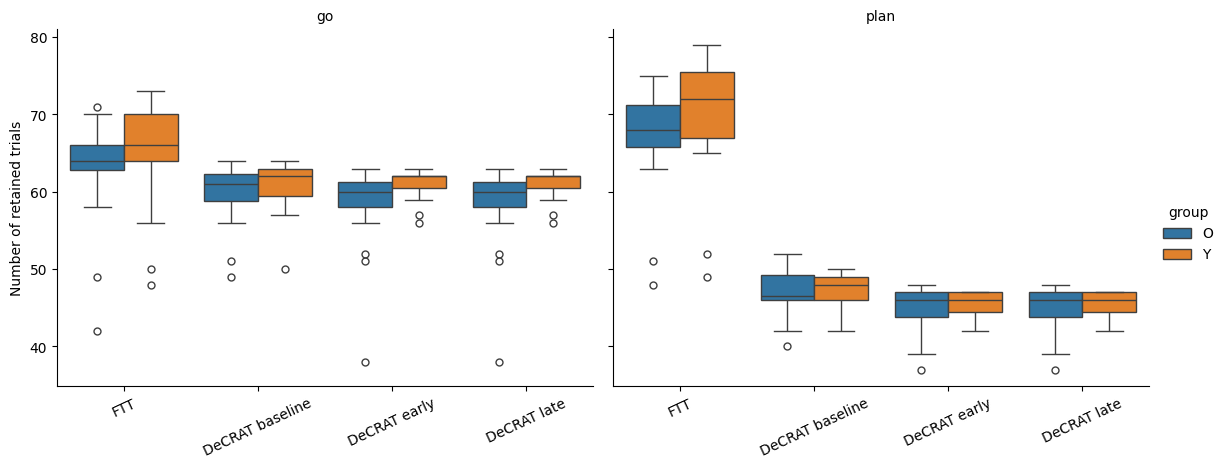

In [5]:
g = sns.catplot(
    data=trial_counts,
    x="condition",
    y="n_epochs",
    hue="group",
    col="task_stage",
    kind="box",
    order=CONDITION_ORDER,
    height=4.5,
    aspect=1.3,
    sharey=True
)

g.set_axis_labels("", "Number of retained trials")
g.set_titles("{col_name}")

for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=25)

plt.show()

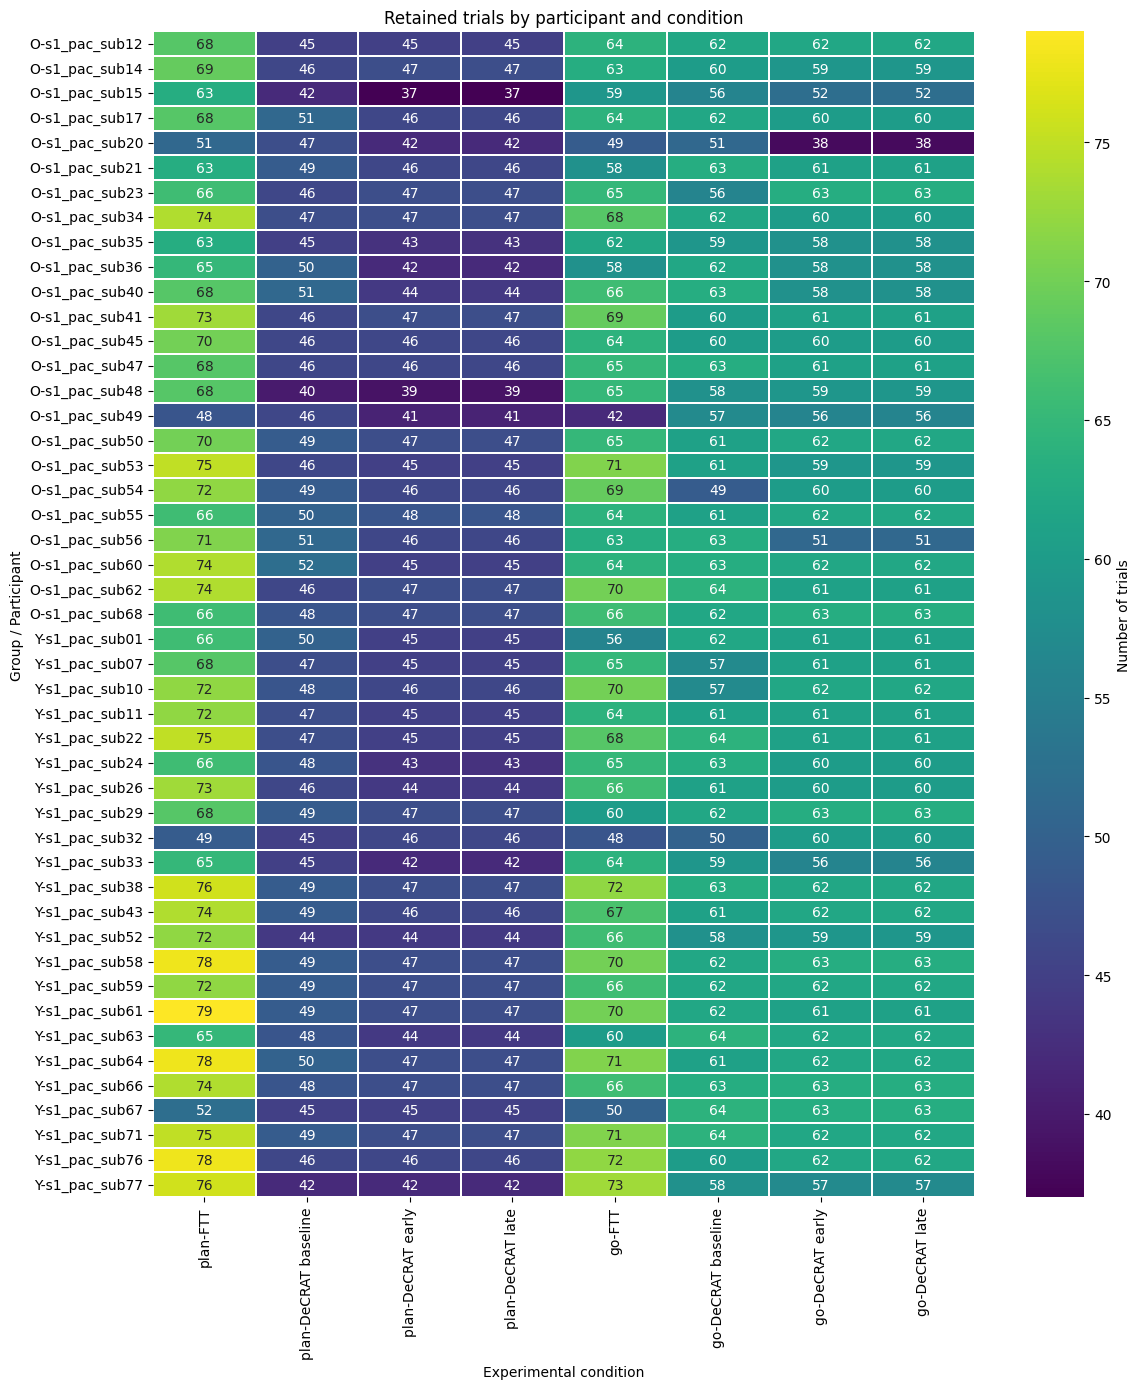

In [6]:
# Participant-level heatmap
trial_pivot = trial_counts.pivot(
    index=["group", "sub"],
    columns=["task_stage", "condition"],
    values="n_epochs"
)

column_order = pd.MultiIndex.from_product(
    [["plan", "go"], CONDITION_ORDER],
    names=["task_stage", "condition"]
)

trial_pivot = trial_pivot.reindex(
    columns=column_order
)

plt.figure(figsize=(12, 14))

sns.heatmap(
    trial_pivot,
    annot=True,
    fmt=".0f",
    cmap="viridis",
    linewidths=0.3,
    cbar_kws={"label": "Number of trials"}
)

plt.title("Retained trials by participant and condition")
plt.xlabel("Experimental condition")
plt.ylabel("Group / Participant")

plt.tight_layout()
plt.show()

Evaluate potential trial-count matching thresholds

In [7]:
CANDIDATE_COUNTS = [
    20, 30, 40, 50, 60, 66, 70, 80
]

rows = []

for threshold in CANDIDATE_COUNTS:

    eligible = trial_counts["n_epochs"] >= threshold

    # Conservative criterion:
    # all eight condition-stage combinations must be available
    participant_eligibility = (
        trial_counts
        .assign(eligible=eligible)
        .groupby(["group", "sub"])
        .agg(
            n_combinations=("n_epochs", "size"),
            all_eligible=("eligible", "all")
        )
    )

    complete_eligible = (
        participant_eligibility["all_eligible"]
        & (participant_eligibility["n_combinations"] == 8)
    )

    retained_trials = (
        eligible.sum() * threshold
    )

    rows.append({
        "target_trials": threshold,
        "eligible_observations": eligible.sum(),
        "eligible_observations_pct": eligible.mean() * 100,

        "eligible_younger": complete_eligible[
            participant_eligibility.index
            .get_level_values("group") == "Y"
        ].sum(),

        "eligible_older": complete_eligible[
            participant_eligibility.index
            .get_level_values("group") == "O"
        ].sum(),

        "eligible_participants_total":
            complete_eligible.sum(),

        "retained_trials_pct_single_subset":
            retained_trials
            / trial_counts["n_epochs"].sum() * 100
    })

threshold_summary = pd.DataFrame(rows)

print(
    threshold_summary.round(2).to_string(index=False)
)

 target_trials  eligible_observations  eligible_observations_pct  eligible_younger  eligible_older  eligible_participants_total  retained_trials_pct_single_subset
            20                    376                     100.00                23              24                           47                              35.52
            30                    376                     100.00                23              24                           47                              53.28
            40                    370                      98.40                23              21                           44                              69.91
            50                    235                      62.50                 0               0                            0                              55.50
            60                    184                      48.94                 0               0                            0                              52.15
            66        

# Repeated trial-count-matched subsampling

In [9]:
# ============================================================
# RESTORE ENVIRONMENT FOR VALIDATION V07
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter
from scipy.stats import skew
from tensorpac import EventRelatedPac
from tensorpac.methods import erpac


# ============================================================
# 1. GENERAL CONFIGURATION
# ============================================================

SFREQ = 500
N_SURROGATES = 200

F_THETA = 6
F_GAMMA = 50

F_PHA = [4, 8]
F_AMP = (30, 80, 5, 1)

# Extended synthetic epoch
times = np.arange(-750, 751) / SFREQ

# Short epoch used for filtering
short_mask = (times >= -0.5) & (times <= 0.5)
short_times = times[short_mask]


# ============================================================
# 2. FINALISED TIME WINDOWS
# ============================================================

validation_windows = {
    "overall": (0.0, 0.4),
    "early": (0.0, 0.15),
    "middle": (0.15, 0.275),
    "late": (0.275, 0.4)
}

window_masks = {
    name: (
        (short_times >= tmin)
        & (short_times < tmax)
    )
    for name, (tmin, tmax)
    in validation_windows.items()
}

WINDOW_NAMES = list(window_masks.keys())

toi_mask = (
    (short_times >= 0)
    & (short_times < 0.4)
)


# ============================================================
# 3. INITIALISE TENSORPAC
# ============================================================

pac = EventRelatedPac(
    f_pha=F_PHA,
    f_amp=F_AMP,
    dcomplex="hilbert",
    cycle=(3, 6),
    verbose=False
)


# ============================================================
# 4. SYNTHETIC SIGNAL GENERATION
# ============================================================

def generate_base_signals_trials(seed, n_trials):

    rng = np.random.default_rng(seed)

    theta_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(n_trials, 1)
    )

    gamma_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(n_trials, 1)
    )

    theta_phase = (
        2 * np.pi * F_THETA * times[None, :]
        + theta_offsets
    )

    theta = np.sin(theta_phase)

    gamma = np.sin(
        2 * np.pi * F_GAMMA * times[None, :]
        + gamma_offsets
    )

    noise = rng.normal(
        0, 0.5,
        size=theta.shape
    )

    return theta_phase, theta, gamma, noise


# ============================================================
# 5. INTRODUCE COUPLING
# ============================================================

def introduce_coupling(
    theta_phase,
    theta,
    gamma,
    noise,
    modulation_depth
):

    gamma_envelope = (
        1 + modulation_depth * np.cos(theta_phase)
    )

    x = theta + gamma_envelope * gamma + noise

    return x


# ============================================================
# 6. PHASE AND AMPLITUDE EXTRACTION
# ============================================================

def extract_phase_amplitude(x, extended=True):

    if extended:

        # Filter extended epoch first
        pha = pac.filter(
            SFREQ, x,
            ftype="phase",
            n_jobs=1
        )

        amp = pac.filter(
            SFREQ, x,
            ftype="amplitude",
            n_jobs=1
        )

        # Crop after filtering
        pha = pha[..., short_mask]
        amp = amp[..., short_mask]

    else:

        # Crop to available short epoch before filtering
        x_short = x[:, short_mask]

        pha = pac.filter(
            SFREQ, x_short,
            ftype="phase",
            n_jobs=1
        )

        amp = pac.filter(
            SFREQ, x_short,
            ftype="amplitude",
            n_jobs=1
        )

    return pha, amp


# ============================================================
# 7. CIRCULAR ERPAC ESTIMATOR
# ============================================================

def compute_erpac(pha, amp):

    rho, _ = erpac(
        np.moveaxis(pha, 1, -1),
        np.moveaxis(amp, 1, -1)
    )

    return rho


# ============================================================
# 8. WINDOW-SPECIFIC ERPAC
# ============================================================

def compute_window_erpac(pha, amp):

    erpac_map = compute_erpac(pha, amp)

    return np.array([
        erpac_map[..., mask].mean()
        for mask in window_masks.values()
    ])


# ============================================================
# 9. CONFIGURATION CHECK
# ============================================================

print("Environment restored successfully.")

print("\nSampling frequency:", SFREQ)
print("Number of surrogates:", N_SURROGATES)
print("Extended epoch samples:", len(times))
print("Short epoch samples:", len(short_times))

print("\nTime windows:")

for name, mask in window_masks.items():
    print(
        f"{name}: {validation_windows[name]} s"
        f" | {mask.sum()} samples"
    )

Environment restored successfully.

Sampling frequency: 500
Number of surrogates: 200
Extended epoch samples: 1501
Short epoch samples: 501

Time windows:
overall: (0.0, 0.4) s | 200 samples
early: (0.0, 0.15) s | 75 samples
middle: (0.15, 0.275) s | 63 samples
late: (0.275, 0.4) s | 62 samples


In [10]:
# Generate 37 synthetic trials
base_signals = generate_base_signals_trials(
    seed=42,
    n_trials=37
)

# Introduce coupling
x_test = introduce_coupling(
    *base_signals,
    modulation_depth=0.10
)

# Extract phase and amplitude
pha_test, amp_test = extract_phase_amplitude(
    x_test,
    extended=False
)

# Compute window-specific ERPAC
erpac_test = compute_window_erpac(
    pha_test,
    amp_test
)

print("Synthetic data shape:", x_test.shape)
print("Phase shape:", pha_test.shape)
print("Amplitude shape:", amp_test.shape)

print("\nERPAC estimates:")

for name, value in zip(WINDOW_NAMES, erpac_test):
    print(f"{name}: {value:.6f}")

assert np.isfinite(erpac_test).all()
assert len(erpac_test) == 4

print("\nFunctionality check passed.")

Synthetic data shape: (37, 1501)
Phase shape: (1, 37, 501)
Amplitude shape: (45, 37, 501)

ERPAC estimates:
overall: 0.268971
early: 0.284755
middle: 0.256645
late: 0.262401

Functionality check passed.


In [11]:
AVAILABLE_TRIAL_COUNTS = [
    37, 45, 60, 70, 80
]

MATCHED_N_TRIALS = 37

SUBSAMPLE_COUNTS = [1, 5, 10, 20]

SUBSAMPLE_MODULATION_DEPTHS = [
    0.0, 0.05, 0.10, 0.20
]

N_SUBSAMPLE_REPEATS = 20

MAX_AVAILABLE_TRIALS = max(
    AVAILABLE_TRIAL_COUNTS
)

MAX_SUBSAMPLES = max(SUBSAMPLE_COUNTS)

SUBSAMPLE_VALIDATION_SEED = 4026

def compute_window_erpac(pha, amp):

    erpac_map = compute_erpac(pha, amp)

    return np.array([
        erpac_map[..., mask].mean()
        for mask in window_masks.values()
    ])


WINDOW_NAMES = list(window_masks.keys())

print(WINDOW_NAMES)


['overall', 'early', 'middle', 'late']


In [12]:
def coordinated_permutations(
    subset_indices,
    global_priorities
):

    # Retrieve random priorities for trials
    # included in the current subset
    subset_priorities = (
        global_priorities[:, subset_indices]
    )

    # Convert priorities to local permutations
    permutations = np.argsort(
        subset_priorities,
        axis=1
    )

    return permutations

def evaluate_repeated_subsampling(
    pha,
    amp,
    subsets,
    global_priorities
):

    n_subsamples = len(subsets)

    n_surrogates = global_priorities.shape[0]

    n_windows = len(WINDOW_NAMES)

    observed = np.empty(
        (n_subsamples, n_windows)
    )

    surrogates = np.empty(
        (
            n_subsamples,
            n_surrogates,
            n_windows
        )
    )

    for k, indices in enumerate(subsets):

        pha_sub = pha[:, indices, :]
        amp_sub = amp[:, indices, :]

        # Observed ERPAC
        observed[k] = compute_window_erpac(
            pha_sub,
            amp_sub
        )

        # Coordinated surrogate permutations
        perms = coordinated_permutations(
            indices,
            global_priorities
        )

        for j, perm in enumerate(perms):

            surrogates[k, j] = (
                compute_window_erpac(
                    pha_sub,
                    amp_sub[:, perm, :]
                )
            )

    return observed, surrogates



In [13]:
def aggregate_subsamples(
    observed,
    surrogates,
    n_subsamples
):

    obs = observed[:n_subsamples]

    sur = surrogates[:n_subsamples]

    # -----------------------------------------
    # Approach A: normalize, then average
    # -----------------------------------------

    sur_mean_A = sur.mean(axis=1)

    sur_sd_A = sur.std(
        axis=1,
        ddof=1
    )

    if (
        not np.isfinite(sur_sd_A).all()
        or np.any(sur_sd_A <= 0)
    ):
        raise ValueError(
            "Invalid surrogate SD"
        )

    individual_z = (
        (obs - sur_mean_A) / sur_sd_A
    )

    z_A = individual_z.mean(axis=0)

    # -----------------------------------------
    # Approach B: average, then normalize
    # -----------------------------------------

    obs_B = obs.mean(axis=0)

    sur_B = sur.mean(axis=0)

    sur_mean_B = sur_B.mean(axis=0)

    sur_sd_B = sur_B.std(
        axis=0,
        ddof=1
    )

    if (
        not np.isfinite(sur_sd_B).all()
        or np.any(sur_sd_B <= 0)
    ):
        raise ValueError(
            "Invalid aggregated surrogate SD"
        )

    z_B = (
        (obs_B - sur_mean_B) / sur_sd_B
    )

    # Empirical upper-tail comparison
    # for the aggregated statistic
    p_B = (
        1 + (sur_B >= obs_B).sum(axis=0)
    ) / (sur_B.shape[0] + 1)

    # -----------------------------------------
    # Collect outputs
    # -----------------------------------------

    rows = []

    for w, window in enumerate(WINDOW_NAMES):

        rows.append({
            "time_window": window,
            "n_subsamples": n_subsamples,

            "observed_mean": obs_B[w],

            "surrogate_mean": sur_mean_B[w],

            "mean_within_subset_surrogate_sd":
                sur_sd_A[:, w].mean(),

            "aggregated_surrogate_sd":
                sur_sd_B[w],

            "z_A": z_A[w],

            "z_B": z_B[w],

            "p_empirical_B": p_B[w],

            "z_within_subsample_SD":
                individual_z[:, w].std(ddof=1)
                if n_subsamples > 1
                else np.nan
        })

    return pd.DataFrame(rows)

In [14]:
from time import perf_counter

all_subsample_results = []

start = perf_counter()

for repeat in range(N_SUBSAMPLE_REPEATS):

    seed = SUBSAMPLE_VALIDATION_SEED + repeat

    # Generate maximum available number of trials
    base_signals = generate_base_signals_trials(
        seed=seed,
        n_trials=MAX_AVAILABLE_TRIALS
    )

    # Random order for nested available trial counts
    rng_order = np.random.default_rng(
        seed + 10000
    )

    trial_order = rng_order.permutation(
        MAX_AVAILABLE_TRIALS
    )

    subsets_by_count = {}
    priorities_by_count = {}

    for n_available in AVAILABLE_TRIAL_COUNTS:

        rng_subset = np.random.default_rng(
            seed + 20000 + n_available
        )

        # When exactly 37 trials are available,
        # every subset contains the same trials
        if n_available == MATCHED_N_TRIALS:

            subsets = np.tile(
                np.arange(MATCHED_N_TRIALS),
                (MAX_SUBSAMPLES, 1)
            )

        else:

            subsets = np.stack([
                np.sort(
                    rng_subset.choice(
                        n_available,
                        size=MATCHED_N_TRIALS,
                        replace=False
                    )
                )
                for _ in range(MAX_SUBSAMPLES)
            ])

        subsets_by_count[n_available] = subsets

        # Random priorities for coordinated shuffling
        rng_sur = np.random.default_rng(
            seed + 30000 + n_available
        )

        priorities_by_count[n_available] = (
            rng_sur.random(
                (N_SURROGATES, n_available)
            )
        )

    # -----------------------------------------
    # Iterate coupling strengths
    # -----------------------------------------

    for depth in SUBSAMPLE_MODULATION_DEPTHS:

        x = introduce_coupling(
            *base_signals,
            modulation_depth=depth
        )

        pha_full, amp_full = (
            extract_phase_amplitude(
                x,
                extended=False
            )
        )

        # -------------------------------------
        # Iterate available trial counts
        # -------------------------------------

        for n_available in AVAILABLE_TRIAL_COUNTS:

            indices = trial_order[:n_available]

            pha = pha_full[:, indices, :]
            amp = amp_full[:, indices, :]

            subsets = subsets_by_count[
                n_available
            ]

            priorities = priorities_by_count[
                n_available
            ]

            # Avoid recomputing identical subsets
            # when only 37 trials are available
            if n_available == MATCHED_N_TRIALS:

                obs, sur = (
                    evaluate_repeated_subsampling(
                        pha,
                        amp,
                        subsets[:1],
                        priorities
                    )
                )

                obs = np.repeat(
                    obs,
                    MAX_SUBSAMPLES,
                    axis=0
                )

                sur = np.repeat(
                    sur,
                    MAX_SUBSAMPLES,
                    axis=0
                )

            else:

                obs, sur = (
                    evaluate_repeated_subsampling(
                        pha,
                        amp,
                        subsets,
                        priorities
                    )
                )

            # Evaluate increasing subsample counts
            for n_subsamples in SUBSAMPLE_COUNTS:

                df = aggregate_subsamples(
                    obs,
                    sur,
                    n_subsamples
                )

                df["repeat"] = repeat + 1

                df["modulation_depth"] = depth

                df["n_available"] = n_available

                df["n_matched"] = (
                    MATCHED_N_TRIALS
                )

                all_subsample_results.append(df)

    print(
        f"Completed repeat "
        f"{repeat + 1}/{N_SUBSAMPLE_REPEATS}"
        f" | Elapsed: "
        f"{(perf_counter() - start)/60:.1f} min"
    )

subsample_results = pd.concat(
    all_subsample_results,
    ignore_index=True
)

print("Validation completed.")

print(subsample_results.shape)

Completed repeat 1/20 | Elapsed: 19.0 min
Completed repeat 2/20 | Elapsed: 35.2 min
Completed repeat 3/20 | Elapsed: 42.3 min
Completed repeat 4/20 | Elapsed: 49.3 min
Completed repeat 5/20 | Elapsed: 56.3 min
Completed repeat 6/20 | Elapsed: 63.3 min
Completed repeat 7/20 | Elapsed: 70.4 min
Completed repeat 8/20 | Elapsed: 77.4 min
Completed repeat 9/20 | Elapsed: 84.3 min
Completed repeat 10/20 | Elapsed: 91.3 min
Completed repeat 11/20 | Elapsed: 98.4 min
Completed repeat 12/20 | Elapsed: 105.5 min
Completed repeat 13/20 | Elapsed: 112.5 min
Completed repeat 14/20 | Elapsed: 119.5 min
Completed repeat 15/20 | Elapsed: 126.6 min
Completed repeat 16/20 | Elapsed: 133.6 min
Completed repeat 17/20 | Elapsed: 152.5 min
Completed repeat 18/20 | Elapsed: 161.5 min
Completed repeat 19/20 | Elapsed: 176.2 min
Completed repeat 20/20 | Elapsed: 185.6 min
Validation completed.
(6400, 14)


In [15]:
# Approaches must agree for one subsample
d_single = subsample_results[
    subsample_results["n_subsamples"] == 1
]

assert np.allclose(
    d_single["z_A"],
    d_single["z_B"]
)

# Approaches must agree when all available
# trials are included in every subsample
d_matched = subsample_results[
    subsample_results["n_available"]
    == MATCHED_N_TRIALS
]

assert np.allclose(
    d_matched["z_A"],
    d_matched["z_B"]
)

print("Implementation checks passed.")

Implementation checks passed.


In [16]:
subsample_summary = (
    subsample_results
    .groupby(
        [
            "n_available",
            "modulation_depth",
            "n_subsamples",
            "time_window"
        ],
        as_index=False
    )
    .agg(
        observed_mean=("observed_mean", "mean"),

        surrogate_mean=("surrogate_mean", "mean"),

        within_subset_surrogate_sd=(
            "mean_within_subset_surrogate_sd",
            "mean"
        ),

        aggregated_surrogate_sd=(
            "aggregated_surrogate_sd",
            "mean"
        ),

        z_A_mean=("z_A", "mean"),
        z_A_SD=("z_A", "std"),

        z_B_mean=("z_B", "mean"),
        z_B_SD=("z_B", "std"),

        n_repeats=("repeat", "nunique")
    )
)

subsample_overall = subsample_summary[
    subsample_summary["time_window"] == "overall"
].copy()

print(
    subsample_overall.round(4).to_string(
        index=False
    )
)

 n_available  modulation_depth  n_subsamples time_window  observed_mean  surrogate_mean  within_subset_surrogate_sd  aggregated_surrogate_sd  z_A_mean  z_A_SD  z_B_mean  z_B_SD  n_repeats
          37              0.00             1     overall         0.2109          0.2105                      0.0156                   0.0156    0.0179  0.9638    0.0179  0.9638         20
          37              0.00             5     overall         0.2109          0.2105                      0.0156                   0.0156    0.0179  0.9638    0.0179  0.9638         20
          37              0.00            10     overall         0.2109          0.2105                      0.0156                   0.0156    0.0179  0.9638    0.0179  0.9638         20
          37              0.00            20     overall         0.2109          0.2105                      0.0156                   0.0156    0.0179  0.9638    0.0179  0.9638         20
          37              0.05             1     overall    

Plotting

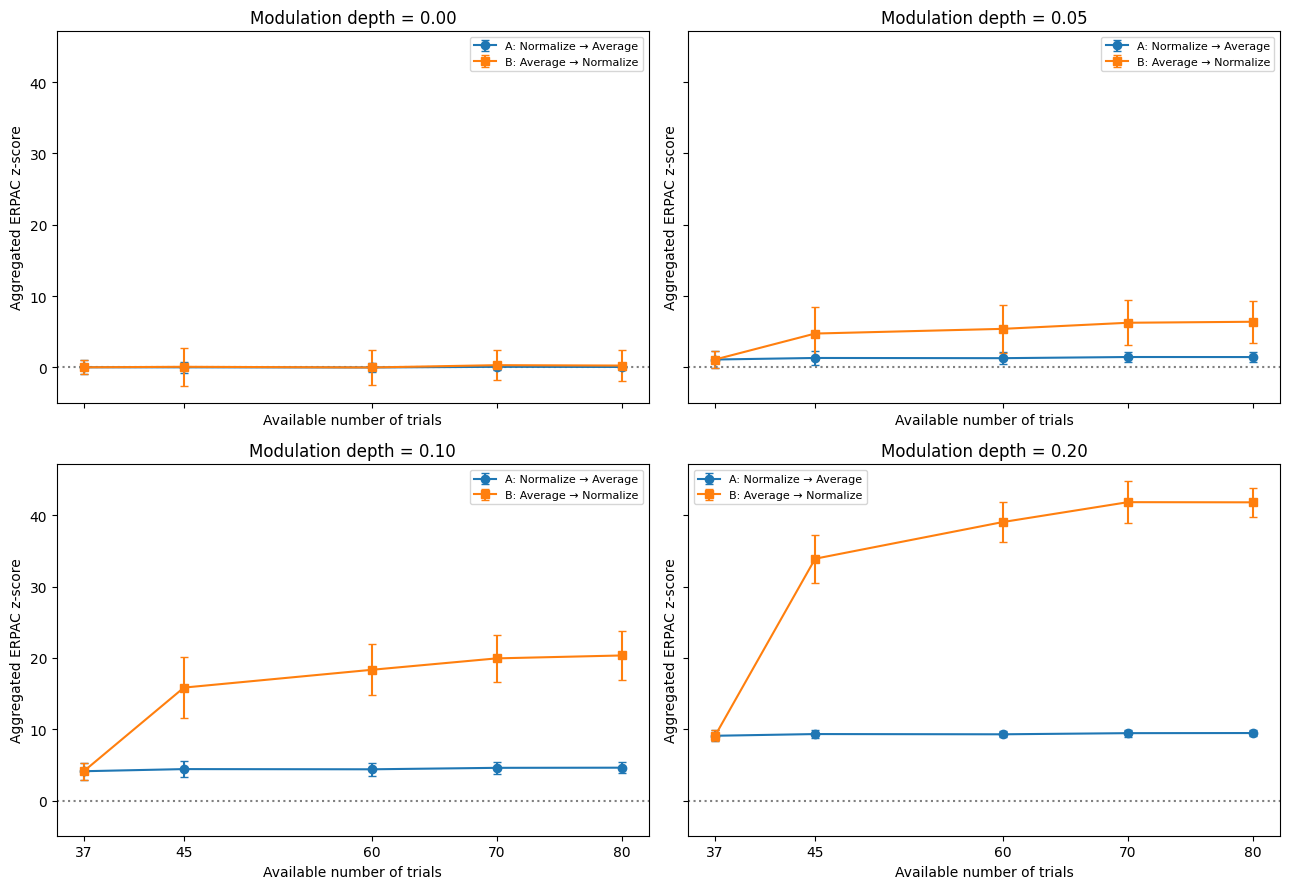

In [20]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True,
    sharey=True
)

for ax, depth in zip(
    axes.flat,
    SUBSAMPLE_MODULATION_DEPTHS
):

    d = subsample_overall[
        (subsample_overall["modulation_depth"]
         == depth)
        & (subsample_overall["n_subsamples"]
           == MAX_SUBSAMPLES)
    ]

    ax.errorbar(
        d["n_available"],
        d["z_A_mean"],
        yerr=d["z_A_SD"],
        marker="o",
        capsize=3,
        label="A: Normalize → Average"
    )

    ax.errorbar(
        d["n_available"],
        d["z_B_mean"],
        yerr=d["z_B_SD"],
        marker="s",
        capsize=3,
        label="B: Average → Normalize"
    )

    ax.axhline(
        0,
        color="grey",
        linestyle=":"
    )

    ax.set_title(
        f"Modulation depth = {depth:.2f}"
    )

    ax.set_xlabel("Available number of trials")

    ax.set_ylabel("Aggregated ERPAC z-score")

    ax.set_xticks(AVAILABLE_TRIAL_COUNTS)

    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

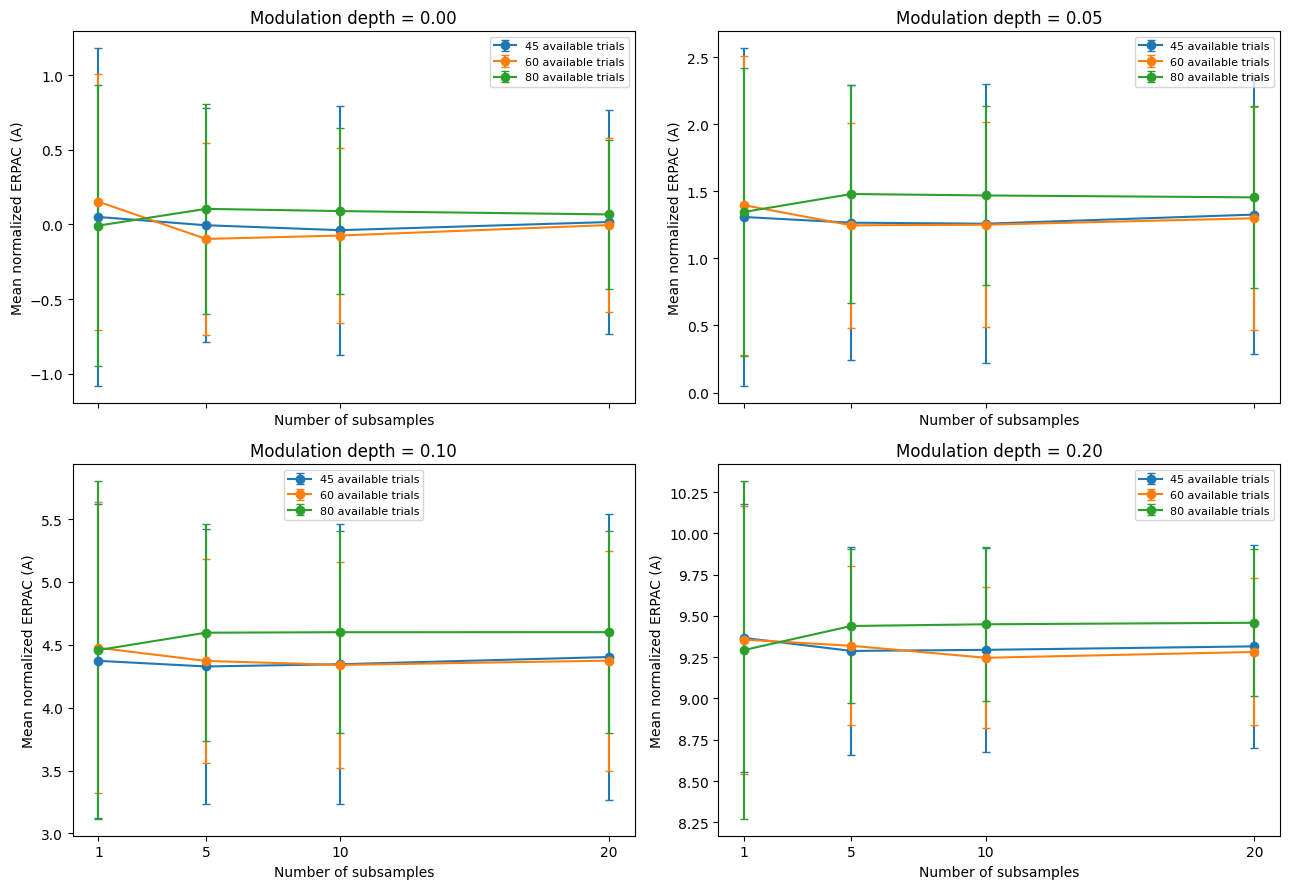

In [21]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True
)

for ax, depth in zip(
    axes.flat,
    SUBSAMPLE_MODULATION_DEPTHS
):

    for n_available in [45, 60, 80]:

        d = subsample_overall[
            (subsample_overall["modulation_depth"]
             == depth)
            & (subsample_overall["n_available"]
               == n_available)
        ]

        ax.errorbar(
            d["n_subsamples"],
            d["z_A_mean"],
            yerr=d["z_A_SD"],
            marker="o",
            capsize=3,
            label=f"{n_available} available trials"
        )

    ax.set_title(
        f"Modulation depth = {depth:.2f}"
    )

    ax.set_xlabel("Number of subsamples")

    ax.set_ylabel("Mean normalized ERPAC (A)")

    ax.set_xticks(SUBSAMPLE_COUNTS)

    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

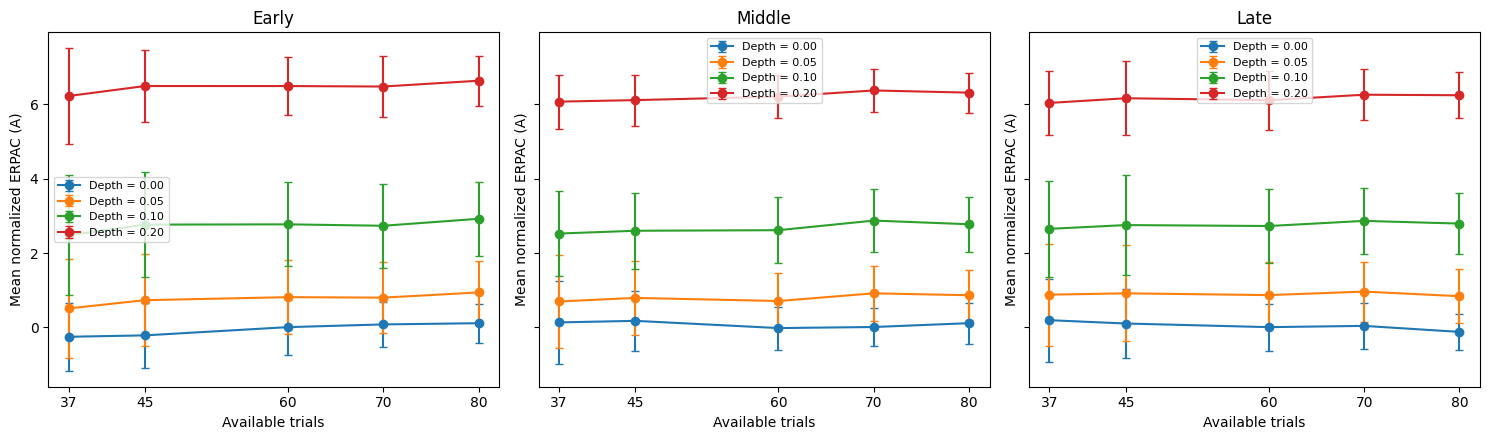

In [22]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharey=True
)

for ax, window in zip(
    axes,
    ["early", "middle", "late"]
):

    for depth in SUBSAMPLE_MODULATION_DEPTHS:

        d = subsample_summary[
            (subsample_summary["time_window"]
             == window)
            & (subsample_summary["modulation_depth"]
               == depth)
            & (subsample_summary["n_subsamples"]
               == MAX_SUBSAMPLES)
        ]

        ax.errorbar(
            d["n_available"],
            d["z_A_mean"],
            yerr=d["z_A_SD"],
            marker="o",
            capsize=3,
            label=f"Depth = {depth:.2f}"
        )

    ax.set_title(window.capitalize())

    ax.set_xlabel("Available trials")

    ax.set_ylabel("Mean normalized ERPAC (A)")

    ax.set_xticks(AVAILABLE_TRIAL_COUNTS)

    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [23]:
from pathlib import Path

validation_dir = Path(
    "validation_repeated_subsampling"
)

validation_dir.mkdir(
    parents=True,
    exist_ok=True
)

subsample_results.to_csv(
    validation_dir
    / "subsample_validation_full.csv",
    index=False
)

subsample_summary.to_csv(
    validation_dir
    / "subsample_validation_summary.csv",
    index=False
)

# Alpha–gamma and beta–gamma ERPAC

In [32]:
FREQUENCY_CONFIGS = {
    "theta-gamma": {
        "phase_band": [4, 8],
        "phase_freq": 6
    },
    "alpha-gamma": {
        "phase_band": [8, 12],
        "phase_freq": 10
    },
    "beta-gamma": {
        "phase_band": [13, 30],
        "phase_freq": 21.5
    }
}

AMPLITUDE_CONFIGS = {
    "narrow": (30, 80, 5, 1),
    "broadband": [30, 80]
}

N_TRIALS_V09 = 37
N_SURROGATES_V09 = 200
N_REPEATS_V09 = 10

GAMMA_CARRIER = 55

MODULATION_DEPTHS_V09 = [0.0, 0.8]

V09_SEED = 6026

def generate_frequency_signals(
    phase_freq,
    modulation_depth,
    seed
):

    rng = np.random.default_rng(seed)

    phase_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(N_TRIALS_V09, 1)
    )

    gamma_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(N_TRIALS_V09, 1)
    )

    low_phase = (
        2 * np.pi * phase_freq * times[None, :]
        + phase_offsets
    )

    low_oscillation = np.sin(low_phase)

    gamma = np.sin(
        2 * np.pi * GAMMA_CARRIER * times[None, :]
        + gamma_offsets
    )

    gamma_envelope = (
        1 + modulation_depth * np.cos(low_phase)
    )

    noise = rng.normal(
        0, 0.5,
        size=low_phase.shape
    )

    x = (
        low_oscillation
        + gamma_envelope * gamma
        + noise
    )

    return x

In [34]:
def extract_frequency_components(
    x,
    phase_band,
    amplitude_band,
    extended=False
):

    pac = EventRelatedPac(
        f_pha=phase_band,
        f_amp=amplitude_band,
        dcomplex="hilbert",
        cycle=(3, 6),
        verbose=False
    )

    if extended:

        x_filter = x

    else:

        x_filter = x[:, short_mask]

    pha = pac.filter(
        SFREQ,
        x_filter,
        ftype="phase",
        n_jobs=1
    )

    amp = pac.filter(
        SFREQ,
        x_filter,
        ftype="amplitude",
        n_jobs=1
    )

    if extended:

        pha = pha[..., short_mask]
        amp = amp[..., short_mask]

    return pha, amp

In [ ]:
def evaluate_frequency_coupling(
    pha,
    amp,
    permutations
):

    observed = compute_window_erpac(
        pha,
        amp
    )

    surrogates = np.stack([
        compute_window_erpac(
            pha,
            amp[:, perm, :]
        )
        for perm in permutations
    ])

    sur_mean = surrogates.mean(axis=0)

    sur_sd = surrogates.std(
        axis=0,
        ddof=1
    )

    if (
        not np.isfinite(sur_sd).all()
        or np.any(sur_sd <= 0)
    ):
        raise ValueError("Invalid surrogate SD")

    z = (observed - sur_mean) / sur_sd

    return pd.DataFrame({
        "time_window": WINDOW_NAMES,
        "observed": observed,
        "surrogate_mean": sur_mean,
        "surrogate_sd": sur_sd,
        "z": z
    })

all_v09_results = []

start = perf_counter()

for repeat in range(N_REPEATS_V09):

    seed = V09_SEED + repeat

    rng_sur = np.random.default_rng(
        seed + 10000
    )

    permutations = np.stack([
        rng_sur.permutation(N_TRIALS_V09)
        for _ in range(N_SURROGATES_V09)
    ])

    for coupling, config in FREQUENCY_CONFIGS.items():

        for depth in MODULATION_DEPTHS_V09:

            x = generate_frequency_signals(
                phase_freq=config["phase_freq"],
                modulation_depth=depth,
                seed=seed
            )

            for amp_method, amp_band in AMPLITUDE_CONFIGS.items():

                for filtering, extended in [
                    ("Extended", True),
                    ("Short", False)
                ]:

                    pha, amp = extract_frequency_components(
                        x,
                        phase_band=config["phase_band"],
                        amplitude_band=amp_band,
                        extended=extended
                    )

                    df = evaluate_frequency_coupling(
                        pha,
                        amp,
                        permutations
                    )

                    df["repeat"] = repeat + 1
                    df["coupling"] = coupling
                    df["modulation_depth"] = depth
                    df["amplitude_filter"] = amp_method
                    df["filtering"] = filtering

                    all_v09_results.append(df)

    print(
        f"Completed repeat "
        f"{repeat + 1}/{N_REPEATS_V09}"
        f" | Elapsed: "
        f"{(perf_counter() - start)/60:.1f} min"
    )

v09_results = pd.concat(
    all_v09_results,
    ignore_index=True
)

print("Validation completed.")

In [ ]:
v09_summary = (
    v09_results
    .groupby(
        [
            "coupling",
            "modulation_depth",
            "amplitude_filter",
            "filtering",
            "time_window"
        ],
        as_index=False
    )
    .agg(
        observed_mean=("observed", "mean"),
        surrogate_mean=("surrogate_mean", "mean"),
        surrogate_SD_mean=("surrogate_sd", "mean"),
        z_mean=("z", "mean"),
        z_SD=("z", "std")
    )
)

v09_overall = v09_summary[
    v09_summary["time_window"] == "overall"
].copy()

print(
    v09_overall.round(4).to_string(index=False)
)

   coupling  modulation_depth amplitude_filter filtering time_window  observed_mean  surrogate_mean  surrogate_SD_mean  z_mean   z_SD
alpha-gamma               0.0        broadband  Extended     overall         0.2191          0.2109             0.0247  0.3190 0.8276
alpha-gamma               0.0        broadband     Short     overall         0.2192          0.2110             0.0248  0.3199 0.8561
alpha-gamma               0.0           narrow  Extended     overall         0.2204          0.2103             0.0152  0.7091 0.8147
alpha-gamma               0.0           narrow     Short     overall         0.2204          0.2103             0.0152  0.7038 0.8230
alpha-gamma               0.8        broadband  Extended     overall         0.9409          0.2095             0.0671 10.9158 0.5162
alpha-gamma               0.8        broadband     Short     overall         0.9402          0.2095             0.0670 10.9123 0.5111
alpha-gamma               0.8           narrow  Extended     o

Plotting

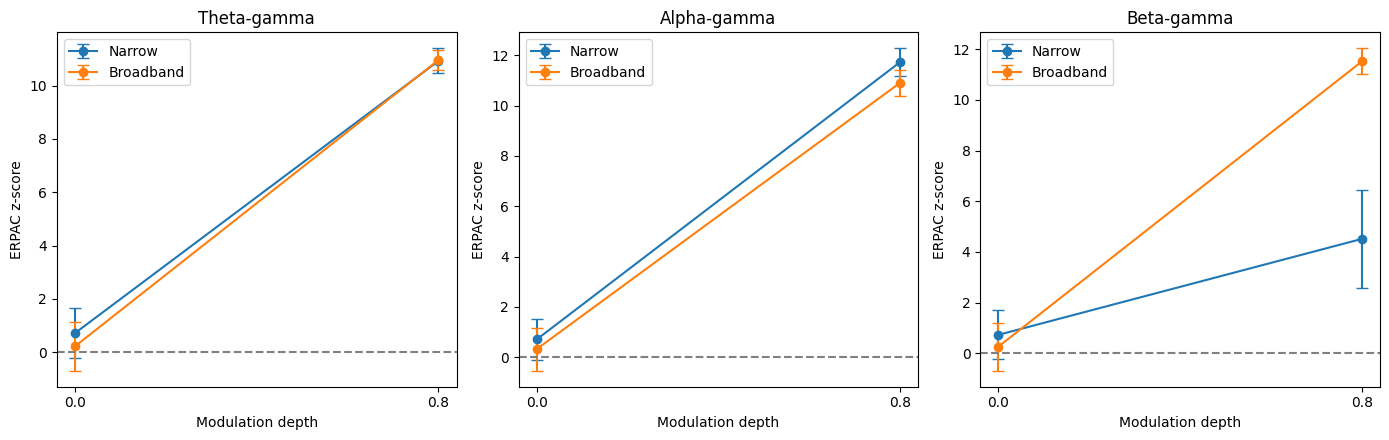

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4.5)
)

for ax, coupling in zip(
    axes,
    FREQUENCY_CONFIGS.keys()
):

    for amp_method in AMPLITUDE_CONFIGS:

        d = v09_overall[
            (v09_overall["coupling"] == coupling)
            & (v09_overall["amplitude_filter"] == amp_method)
            & (v09_overall["filtering"] == "Short")
        ].sort_values("modulation_depth")

        ax.errorbar(
            d["modulation_depth"],
            d["z_mean"],
            yerr=d["z_SD"],
            marker="o",
            capsize=4,
            label=amp_method.capitalize()
        )

    ax.axhline(
        0,
        color="grey",
        linestyle="--"
    )

    ax.set_title(coupling.capitalize())
    ax.set_xlabel("Modulation depth")
    ax.set_ylabel("ERPAC z-score")
    ax.set_xticks(MODULATION_DEPTHS_V09)
    ax.legend()

plt.tight_layout()
plt.show()

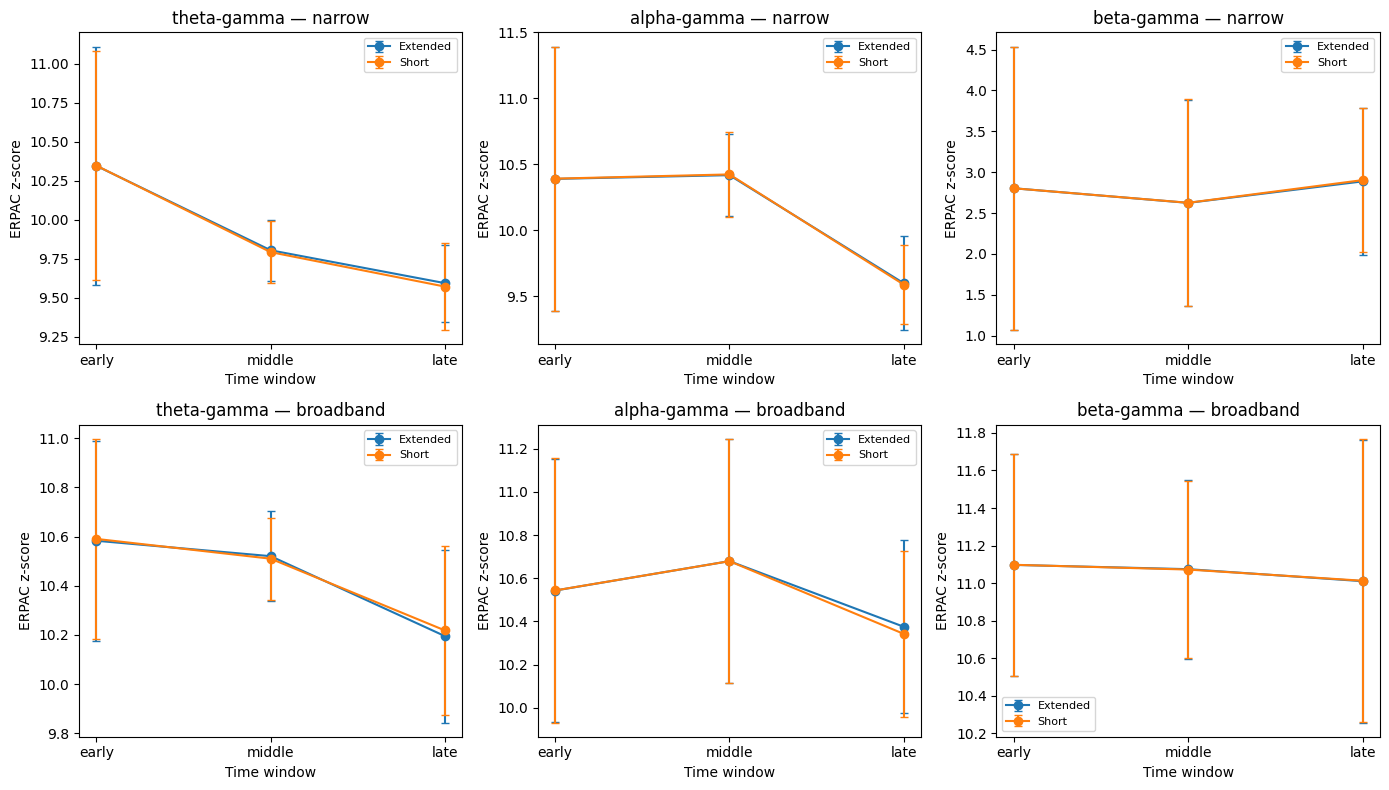

In [ ]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

for i, amp_method in enumerate(AMPLITUDE_CONFIGS):

    for j, coupling in enumerate(FREQUENCY_CONFIGS):

        ax = axes[i, j]

        for filtering in ["Extended", "Short"]:

            d = v09_summary[
                (v09_summary["coupling"] == coupling)
                & (v09_summary["modulation_depth"] == 0.8)
                & (v09_summary["amplitude_filter"] == amp_method)
                & (v09_summary["filtering"] == filtering)
            ].set_index("time_window")

            d = d.loc[["early", "middle", "late"]]

            ax.errorbar(
                d.index,
                d["z_mean"],
                yerr=d["z_SD"],
                marker="o",
                capsize=3,
                label=filtering
            )

        ax.set_title(
            f"{coupling} — {amp_method}"
        )

        ax.set_xlabel("Time window")
        ax.set_ylabel("ERPAC z-score")
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
validation_dir = Path(
    "validation_frequency_couplings"
)

validation_dir.mkdir(
    parents=True,
    exist_ok=True
)

v09_results.to_csv(
    validation_dir / "frequency_validation_full.csv",
    index=False
)

v09_summary.to_csv(
    validation_dir / "frequency_validation_summary.csv",
    index=False
)

# Real EEG validaiton

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter
from tensorpac import EventRelatedPac
from tensorpac.methods import erpac

# ============================================================
# DATA CONFIGURATION
# ============================================================

PCA_ROI_TC_DIR = Path(
    r"F:\# study 2\eeg_data\erpac\PCA\stcs_ave_vtx"
)

GROUP = "Y"
SUBJECT = "s1_pac_sub01"
TASK = "FTT"
STAGE = "plan"
ROI = "M1"

# ============================================================
# ERPAC CONFIGURATION
# ============================================================

COUPLINGS = {
    "theta_gamma": ([4, 8], [30, 80]),
    "alpha_gamma": ([8, 12], [30, 80]),
    "beta_gamma": ([13, 30], [30, 80])
}

N_MATCHED_TRIALS = 37
N_SUBSAMPLES = 10
N_SURROGATES = 200

SEED = 7026

TIME_WINDOWS = {
    "overall": (0.0, 0.4),
    "early": (0.0, 0.15),
    "middle": (0.15, 0.275),
    "late": (0.275, 0.4)
}

WINDOW_NAMES = list(TIME_WINDOWS.keys())

subject_dir = (
    PCA_ROI_TC_DIR / GROUP / SUBJECT
)

files = sorted(
    subject_dir.rglob("*_pca_roi_tc.npz")
)

print("Files found:", len(files))


def read_metadata(npz, key):
    return str(npz[key].item())


matching_files = []

for file in files:

    with np.load(file, allow_pickle=True) as npz:

        if (
            read_metadata(npz, "task") == TASK
            and read_metadata(npz, "task_stage") == STAGE
            and read_metadata(npz, "roi") == ROI
        ):
            matching_files.append(file)

assert len(matching_files) == 1, (
    f"Expected one matching file, "
    f"found {len(matching_files)}"
)

file = matching_files[0]

print("Selected file:", file.name)

with np.load(file, allow_pickle=True) as npz:

    data = np.asarray(
        npz["data"],
        dtype=float
    )

    times = np.asarray(
        npz["times"],
        dtype=float
    )

# Expected dimensions: trials × 1 × time
assert data.ndim == 3
assert data.shape[1] == 1
assert data.shape[2] == len(times)

# Remove singleton ROI dimension
x = data[:, 0, :]

n_trials, n_times = x.shape

sfreq = 1 / np.median(np.diff(times))

assert np.isfinite(x).all()
assert n_trials >= N_MATCHED_TRIALS
assert np.isclose(sfreq, 500)

print("\nData shape:", x.shape)
print("Available trials:", n_trials)
print("Sampling frequency:", sfreq)
print("Epoch:", times[0], "to", times[-1], "s")

Files found: 32
Selected file: FTT_plan_M1_pca_roi_tc.npz

Data shape: (66, 501)
Available trials: 66
Sampling frequency: 499.99999999999955
Epoch: -0.5 to 0.5 s


In [37]:
window_masks = {
    name: (
        (times >= tmin)
        & (times < tmax)
    )
    for name, (tmin, tmax)
    in TIME_WINDOWS.items()
}

for name, mask in window_masks.items():

    assert mask.any(), (
        f"Empty time window: {name}"
    )

    print(
        f"{name}: "
        f"{TIME_WINDOWS[name]} s "
        f"| {mask.sum()} samples"
    )

overall: (0.0, 0.4) s | 200 samples
early: (0.0, 0.15) s | 75 samples
middle: (0.15, 0.275) s | 63 samples
late: (0.275, 0.4) s | 62 samples


In [38]:
rng = np.random.default_rng(SEED)

# No repeated sampling if exactly 37 trials
K = (
    1 if n_trials == N_MATCHED_TRIALS
    else N_SUBSAMPLES
)

# Random subsets without replacement
subsets = np.stack([
    np.sort(
        rng.choice(
            n_trials,
            size=N_MATCHED_TRIALS,
            replace=False
        )
    )
    for _ in range(K)
])

# Independent trial permutations within each subset
permutations = np.stack([
    np.stack([
        rng.permutation(N_MATCHED_TRIALS)
        for _ in range(N_SURROGATES)
    ])
    for _ in range(K)
])

print("Trial subsets:", subsets.shape)
print("Surrogate permutations:", permutations.shape)

# Number of times each original trial is included
trial_usage = np.bincount(
    subsets.ravel(),
    minlength=n_trials
)

print(
    "Unique trials included:",
    np.sum(trial_usage > 0),
    "/",
    n_trials
)

print("Minimum trial usage:", trial_usage.min())
print("Maximum trial usage:", trial_usage.max())

Trial subsets: (10, 37)
Surrogate permutations: (10, 200, 37)
Unique trials included: 66 / 66
Minimum trial usage: 1
Maximum trial usage: 8


In [39]:
def extract_components(x, phase_band, amp_band):

    pac = EventRelatedPac(
        f_pha=phase_band,
        f_amp=amp_band,
        dcomplex="hilbert",
        cycle=(3, 6),
        verbose=False
    )

    pha = pac.filter(
        sfreq,
        x,
        ftype="phase",
        n_jobs=1
    )

    amp = pac.filter(
        sfreq,
        x,
        ftype="amplitude",
        n_jobs=1
    )

    return pha, amp


def compute_erpac(pha, amp):

    rho, _ = erpac(
        np.moveaxis(pha, 1, -1),
        np.moveaxis(amp, 1, -1)
    )

    return rho


def compute_window_erpac(erpac_map):

    return np.array([
        erpac_map[..., mask].mean()
        for mask in window_masks.values()
    ])

Implement the complete surrogate pipeline

In [40]:
def evaluate_subsample(
    pha,
    amp,
    indices,
    perms
):

    pha_sub = pha[:, indices, :]
    amp_sub = amp[:, indices, :]

    # Observed ERPAC
    observed_map = compute_erpac(
        pha_sub,
        amp_sub
    )

    observed = compute_window_erpac(
        observed_map
    )

    # Surrogate ERPAC
    surrogates = np.stack([
        compute_window_erpac(
            compute_erpac(
                pha_sub,
                amp_sub[:, perm, :]
            )
        )
        for perm in perms
    ])

    # Surrogate distribution statistics
    surrogate_mean = surrogates.mean(axis=0)

    surrogate_sd = surrogates.std(
        axis=0,
        ddof=1
    )

    # Validate normalization inputs
    assert np.isfinite(observed).all()
    assert np.isfinite(surrogates).all()

    if np.any(surrogate_sd <= 0):
        raise ValueError(
            "Zero or negative surrogate SD"
        )

    # Within-subset z-normalization
    z = (
        observed - surrogate_mean
    ) / surrogate_sd

    df = pd.DataFrame({
        "time_window": WINDOW_NAMES,
        "observed": observed,
        "surrogate_mean": surrogate_mean,
        "surrogate_sd": surrogate_sd,
        "z": z
    })

    return df, observed_map, surrogates

In [41]:
all_results = []

observed_maps = {}

surrogate_distributions = {}

start = perf_counter()

for coupling, (phase_band, amp_band) in COUPLINGS.items():

    print(f"\nProcessing {coupling}")

    # Filter all available trials once
    pha, amp = extract_components(
        x,
        phase_band,
        amp_band
    )

    print("Phase shape:", pha.shape)
    print("Amplitude shape:", amp.shape)

    coupling_maps = []

    coupling_surrogates = []

    for k in range(K):

        df, obs_map, sur = evaluate_subsample(
            pha,
            amp,
            subsets[k],
            permutations[k]
        )

        df["coupling"] = coupling
        df["subsample"] = k + 1
        df["n_available"] = n_trials
        df["n_matched"] = N_MATCHED_TRIALS

        all_results.append(df)

        coupling_maps.append(obs_map)

        coupling_surrogates.append(sur)

        print(
            f"  Subsample {k + 1}/{K}"
        )

    observed_maps[coupling] = np.stack(
        coupling_maps
    )

    surrogate_distributions[coupling] = np.stack(
        coupling_surrogates
    )

    print(
        f"Elapsed: "
        f"{perf_counter() - start:.1f} s"
    )

real_eeg_results = pd.concat(
    all_results,
    ignore_index=True
)

print("\nValidation completed.")
print("Output shape:", real_eeg_results.shape)


Processing theta_gamma
Phase shape: (1, 66, 501)
Amplitude shape: (1, 66, 501)
  Subsample 1/10
  Subsample 2/10
  Subsample 3/10
  Subsample 4/10
  Subsample 5/10
  Subsample 6/10
  Subsample 7/10
  Subsample 8/10
  Subsample 9/10
  Subsample 10/10
Elapsed: 3.1 s

Processing alpha_gamma
Phase shape: (1, 66, 501)
Amplitude shape: (1, 66, 501)
  Subsample 1/10
  Subsample 2/10
  Subsample 3/10
  Subsample 4/10
  Subsample 5/10
  Subsample 6/10
  Subsample 7/10
  Subsample 8/10
  Subsample 9/10
  Subsample 10/10
Elapsed: 7.2 s

Processing beta_gamma
Phase shape: (1, 66, 501)
Amplitude shape: (1, 66, 501)
  Subsample 1/10
  Subsample 2/10
  Subsample 3/10
  Subsample 4/10
  Subsample 5/10
  Subsample 6/10
  Subsample 7/10
  Subsample 8/10
  Subsample 9/10
  Subsample 10/10
Elapsed: 8.4 s

Validation completed.
Output shape: (120, 9)


Aggregate the results

In [42]:
# Window-speciifc estimates
real_eeg_summary = (
    real_eeg_results
    .groupby(
        ["coupling", "time_window"],
        as_index=False
    )
    .agg(
        observed_mean=("observed", "mean"),

        surrogate_mean=("surrogate_mean", "mean"),

        surrogate_SD_mean=("surrogate_sd", "mean"),

        z_mean=("z", "mean"),

        z_subsample_SD=("z", "std"),

        n_subsamples=("subsample", "nunique")
    )
)

real_eeg_summary["time_window"] = pd.Categorical(
    real_eeg_summary["time_window"],
    categories=WINDOW_NAMES,
    ordered=True
)

real_eeg_summary = (
    real_eeg_summary
    .sort_values(
        ["coupling", "time_window"]
    )
    .reset_index(drop=True)
)

print(
    real_eeg_summary.round(6).to_string(
        index=False
    )
)

   coupling time_window  observed_mean  surrogate_mean  surrogate_SD_mean    z_mean  z_subsample_SD  n_subsamples
alpha_gamma     overall       0.193014        0.210102           0.019677 -0.866308        0.896126            10
alpha_gamma       early       0.195995        0.210668           0.031347 -0.485497        1.149369            10
alpha_gamma      middle       0.186939        0.209289           0.034540 -0.635474        0.876084            10
alpha_gamma        late       0.195580        0.210243           0.034816 -0.400068        0.664822            10
 beta_gamma     overall       0.223337        0.209896           0.019245  0.669727        1.150473            10
 beta_gamma       early       0.226135        0.209877           0.030194  0.523791        1.240036            10
 beta_gamma      middle       0.225436        0.210818           0.034653  0.409964        0.989060            10
 beta_gamma        late       0.217819        0.208983           0.033636  0.272255     

Plotting

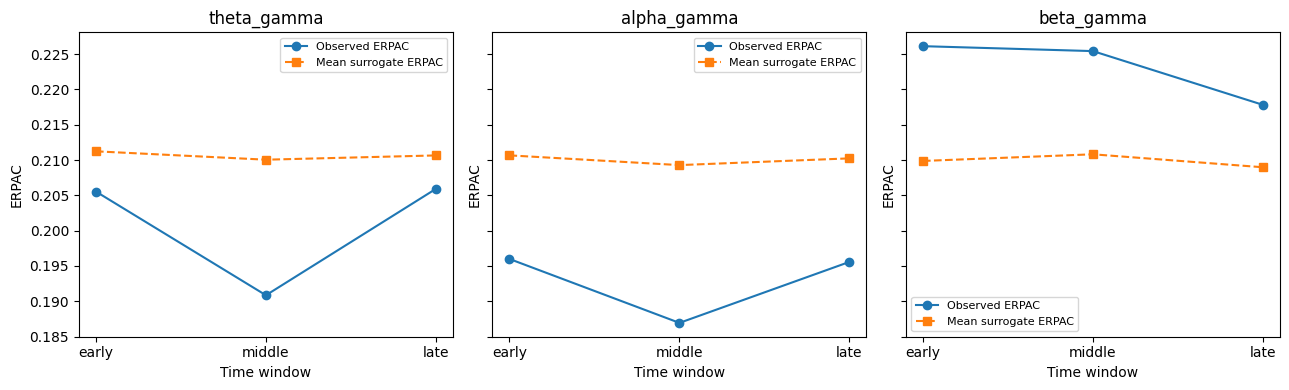

In [43]:
# Observed versus surrogate ERPAC
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    sharey=True
)

for ax, coupling in zip(
    axes,
    COUPLINGS.keys()
):

    d = real_eeg_summary[
        (real_eeg_summary["coupling"] == coupling)
        & (real_eeg_summary["time_window"] != "overall")
    ]

    ax.plot(
        d["time_window"],
        d["observed_mean"],
        marker="o",
        label="Observed ERPAC"
    )

    ax.plot(
        d["time_window"],
        d["surrogate_mean"],
        marker="s",
        linestyle="--",
        label="Mean surrogate ERPAC"
    )

    ax.set_title(coupling)
    ax.set_xlabel("Time window")
    ax.set_ylabel("ERPAC")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

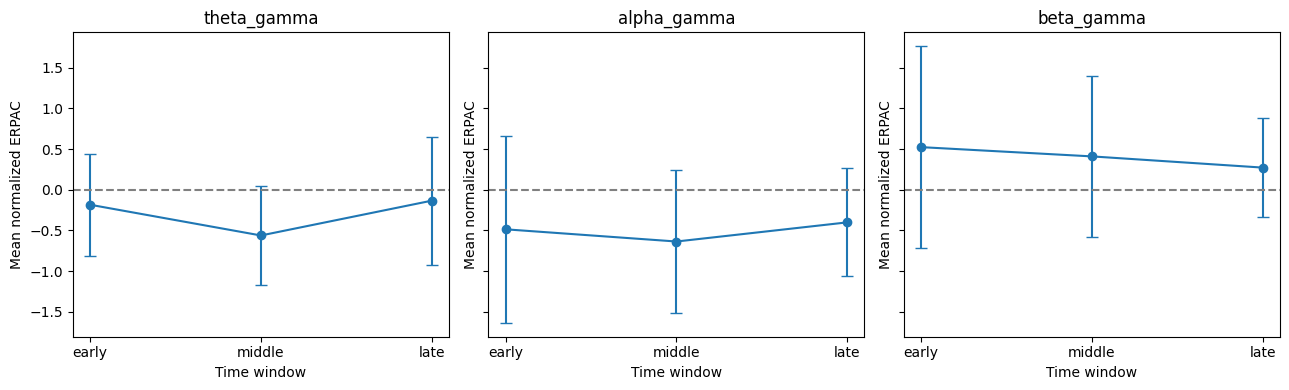

In [44]:
# Surrogate-normalized ERPAC
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    sharey=True
)

for ax, coupling in zip(
    axes,
    COUPLINGS.keys()
):

    d = real_eeg_summary[
        (real_eeg_summary["coupling"] == coupling)
        & (real_eeg_summary["time_window"] != "overall")
    ]

    ax.errorbar(
        d["time_window"],
        d["z_mean"],
        yerr=d["z_subsample_SD"],
        marker="o",
        capsize=4
    )

    ax.axhline(
        0,
        color="grey",
        linestyle="--"
    )

    ax.set_title(coupling)
    ax.set_xlabel("Time window")
    ax.set_ylabel("Mean normalized ERPAC")

plt.tight_layout()
plt.show()

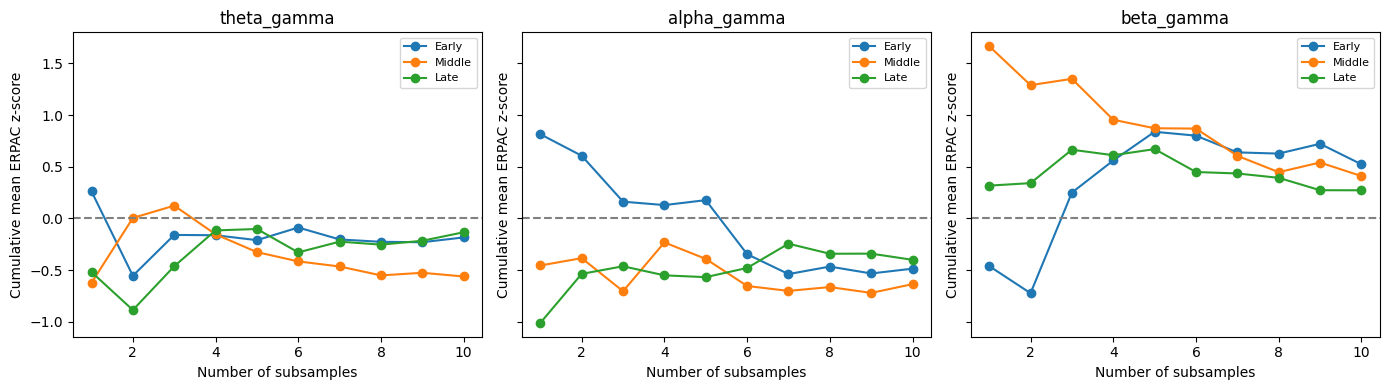

In [45]:
# Stability across subsampling iterations
fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4),
    sharey=True
)

for ax, coupling in zip(
    axes,
    COUPLINGS.keys()
):

    for window in ["early", "middle", "late"]:

        d = real_eeg_results[
            (real_eeg_results["coupling"] == coupling)
            & (real_eeg_results["time_window"] == window)
        ].sort_values("subsample")

        cumulative_z = (
            d["z"].expanding().mean()
        )

        ax.plot(
            d["subsample"],
            cumulative_z,
            marker="o",
            label=window.capitalize()
        )

    ax.axhline(
        0,
        color="grey",
        linestyle="--"
    )

    ax.set_title(coupling)
    ax.set_xlabel("Number of subsamples")
    ax.set_ylabel("Cumulative mean ERPAC z-score")

    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

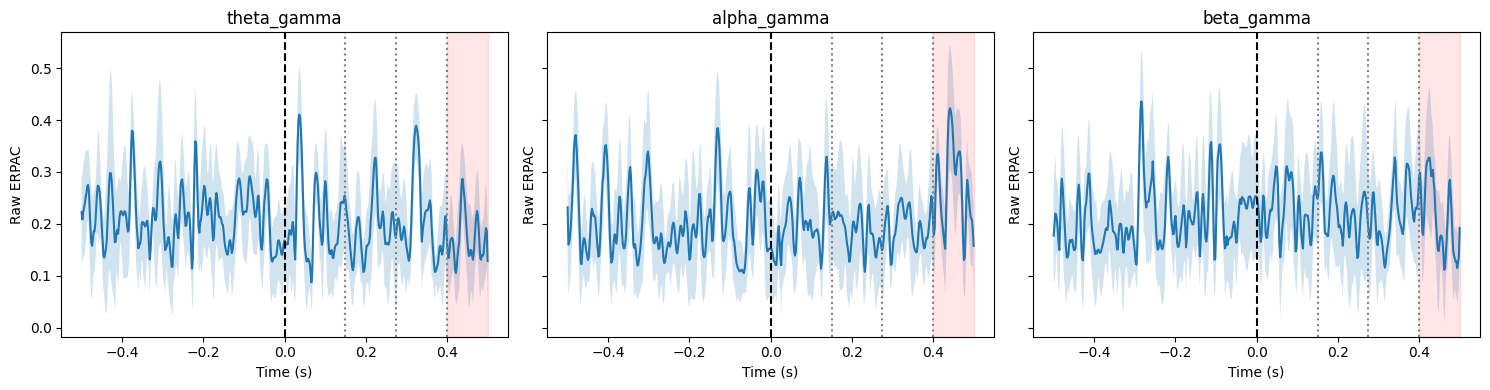

In [46]:
# Inspect the raw ERPAC time courses
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    sharey=True
)

for ax, coupling in zip(
    axes,
    COUPLINGS.keys()
):

    maps = observed_maps[coupling]

    # Average across phase/amplitude dimensions
    # Result: subsamples × time
    timecourses = maps.mean(axis=(1, 2))

    mean_tc = timecourses.mean(axis=0)

    sd_tc = timecourses.std(
        axis=0,
        ddof=1
    )

    ax.plot(
        times,
        mean_tc
    )

    ax.fill_between(
        times,
        mean_tc - sd_tc,
        mean_tc + sd_tc,
        alpha=0.2
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--"
    )

    ax.axvspan(
        0.4,
        times[-1],
        color="red",
        alpha=0.1,
        label="Excluded"
    )

    for boundary in [0.15, 0.275, 0.4]:

        ax.axvline(
            boundary,
            color="grey",
            linestyle=":"
        )

    ax.set_title(coupling)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Raw ERPAC")

plt.tight_layout()
plt.show()

In [47]:
# Saving results
validation_dir = Path(
    "validation_real_eeg"
)

validation_dir.mkdir(
    parents=True,
    exist_ok=True
)

real_eeg_results.to_csv(
    validation_dir / "real_eeg_subsample_results.csv",
    index=False
)

real_eeg_summary.to_csv(
    validation_dir / "real_eeg_summary.csv",
    index=False
)

# Save selected trial indices for reproducibility
np.savez_compressed(
    validation_dir / "real_eeg_trial_selection.npz",
    subsets=subsets,
    permutations=permutations,
    seed=SEED
)